# Pronóstico semanal de dengue por departamento

**Competencia:** AA-V-2026-II-pronosticos-nn-rnn-lstm-tcn · equipo *Pandebono Predictors*
**Materia:** Aprendizaje Automático V, Maestría en Inteligencia Artificial Aplicada, Universidad ICESI

**Integrantes**

| Integrante | Código |
| --- | --- |
| Jairo Andrés Valencia | A00429914 |
| Juan Camilo Macías Navarrete | A00427476 |

## Para qué sirve el pronóstico

El dengue no se distribuye igual en los 31 departamentos del archivo. Un error en Valle del Cauca, Santander, Tolima o Antioquia pesa mucho más en el MSE que el mismo error relativo en Vaupés o Guainía, porque la métrica eleva al cuadrado la diferencia de casos. Anticipar la semana y el departamento del próximo pico sirve para mover fumigación, alerta comunitaria y camas antes de que el servicio se sature. El modelo tiene que ser útil para esa decisión, no solo para ajustar una curva nacional.

## Resumen de la decisión

- El tablero público mide julio a diciembre de 2025. El privado, que define el puesto, mide enero a junio. Por eso el modelo final se elige con el error del primer semestre en walk-forward: cada año se pronostica desde la última semana del año anterior, igual que 2025.
- Ninguna red sola le gana a las bases epidemiológicas por horizonte (etapa 3) en ese primer semestre. Mezcladas sí: 25 % TCN + 25 % MLP + 50 % bases baja el MSE medio de 2014-2023 de 3534 a 3310 y gana 7 de 10 años. Con un peso para la red que depende de la región, estimado solo con años anteriores, 2016-2023 baja de 3696 a 3651. Con pesos de B, TCN y MLP buscados por región (apilamiento) y el final del primer semestre llevado hacia el nivel del segundo, 2016-2023 queda en 3355, y en 3230 si ese nivel se toma por región (Costa e interior).
- El segundo semestre se calibra con el tablero público. Dos envíos de medición dieron el nivel real de julio a diciembre por región (0,95 de B en la Costa y 0,887 en el interior); con eso, una combinación lineal de envíos ya subidos da 1689,04 exacto, frente a 2048,50 de B. Esos dos niveles son los que usa el final del primer semestre.
- Enero de 2025 arranca desde un diciembre de 2024 muy alto, y la historia no permite saber si 2025 cayó de golpe o siguió desde ese nivel. Las dos selecciones finales de Kaggle son el apilado con nivel por región, el mejor modelo del walk-forward, y B con nivel por región, que cubre una caída fuerte. Un envío de prueba con el segundo semestre de las redes empeoró el público (2050,42 frente a 1971,62): en 2025 la lectura de las redes no le ganó a B, y por eso la segunda selección cubre ese lado.

## Cómo está organizado el cuaderno

| Fase de la rúbrica | Qué se entrega |
| --- | --- |
| 1. Análisis exploratorio (0.5) | Integridad, estacionalidad, heterogeneidad regional, correlaciones con rezago, lotes de reporte mensual y el cierre de 2024 |
| 2. MLP (0.5) | Etapa 1: variante cercana al código base y variante optimizada. Etapa 4: MLP de 26 horizontes en walk-forward |
| 3. RNN (1.0) | Igual que el MLP |
| 4. LSTM y GRU (1.5) | Igual que el MLP, más los experimentos de diseño de la etapa 4, hechos con GRU |
| 5. TCN (1.0) | Igual que el MLP, con el campo receptivo ajustado a cada ventana |
| 6. Elección (0.5) | Tabla walk-forward del primer semestre, gráficos de 2025, archivos finales y cobertura de escenarios |

Hay cuatro vueltas de modelado:

1. **Etapa 1.** Comparación de arquitecturas con objetivo directo (los casos de la semana), validada en 2024.
2. **Etapa 2.** Las redes corrigen un perfil estacional en vez de inventar el nivel.
3. **Etapa 3.** Bases epidemiológicas por horizonte, sin red. Es la referencia estadística y el segundo semestre del envío final.
4. **Etapa 4.** Redes de 26 semanas para el primer semestre, evaluadas año por año desde el cierre de diciembre, y su mezcla con la etapa 3.

### Librerias, rutas y semilla

Estas funciones solo preparan el entorno. La semilla fija los pesos iniciales para que la comparacion entre arquitecturas no dependa del azar.

In [1]:
import copy
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, Dataset

CLIMATE_COLS = [
    "precip_chirps_mm",
    "temp_media_C",
    "temp_max_C",
    "temp_min_C",
    "punto_rocio_C",
    "humedad_suelo_capa1",
    "evapotranspiracion_mm",
    "radiacion_solar_MJ_m2",
    "viento_vel_m_s",
    "viento_dir_grados",
    "presion_superficial_hPa",
]

ROLL_COLS = [
    "precip_chirps_mm",
    "temp_media_C",
    "temp_min_C",
    "humedad_suelo_capa1",
]

ANOMALY_COLS = [c for c in CLIMATE_COLS if c != "viento_dir_grados"]


def repo_root() -> Path:
    aqui = Path.cwd().resolve()
    for carpeta in [aqui, *list(aqui.parents)[:4]]:
        if (carpeta / "data" / "train.parquet").exists():
            return carpeta
    return aqui


def resolve_data_dir() -> Path:
    seeds = [repo_root(), Path.cwd()]
    try:
        seeds.append(Path(__file__).resolve().parent)
    except NameError:
        pass
    candidates = [
        Path("/kaggle/input/competitions/aa-v-2026-ii-pronosticos-nn-rnn-lstm-tcn"),
        Path("/kaggle/input/aa-v-2026-ii-pronosticos-nn-rnn-lstm-tcn"),
    ]
    for seed in seeds:
        candidates.extend([seed / "data", seed])
    for candidate in candidates:
        if (candidate / "train.parquet").exists():
            return candidate
    raise FileNotFoundError("No se encontro train.parquet en las carpetas de datos esperadas.")


def resolve_device() -> torch.device:
    if torch.cuda.is_available():
        return torch.device("cuda")
    return torch.device("cpu")


def reset_seed(seed: int = 42) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

### Variables sin mirar el futuro

Para un año Y, la media del departamento, el perfil de la semana, el año anterior y las anclas de 8 y 26 semanas salen solo de años anteriores a Y. La semana que se va a predecir no aporta su conteo de casos.

In [2]:
def _lookup_week(mapping: pd.Series, weeks: pd.Series, default: float) -> pd.Series:
    values = weeks.map(mapping)
    if values.isna().any() and 52 in mapping.index:
        values = values.fillna(float(mapping.loc[52]))
    return values.fillna(default).astype(float)


def build_features(df: pd.DataFrame) -> pd.DataFrame:
    """Una fila por departamento y semana desde 2008. El contexto de cada año usa solo años previos."""
    frame = df.sort_values(["id_departamento", "anio", "semana"]).copy()
    if "casos_dengue" not in frame.columns:
        frame["casos_dengue"] = np.nan

    parts: list[pd.DataFrame] = []
    for _, group in frame.groupby("id_departamento", sort=False):
        group = group.sort_values(["anio", "semana"]).reset_index(drop=True)
        rolled = group[ROLL_COLS].rolling(4, min_periods=1).mean()
        for col in ROLL_COLS:
            group[f"{col}_roll4"] = rolled[col].to_numpy()
        radians = np.deg2rad(group["viento_dir_grados"].to_numpy())
        group["viento_sin"] = np.sin(radians)
        group["viento_cos"] = np.cos(radians)
        group["week_sin"] = np.sin(2 * np.pi * group["semana"] / 52)
        group["week_cos"] = np.cos(2 * np.pi * group["semana"] / 52)

        yearly: list[pd.DataFrame] = []
        for year, current in group.groupby("anio", sort=True):
            history = group[group["anio"] < year]
            previous = group[group["anio"] == year - 1]
            known_history = history[history["casos_dengue"].notna()]
            known_previous = previous[previous["casos_dengue"].notna()]
            if known_history.empty or known_previous.empty:
                continue

            department_mean = float(known_history["casos_dengue"].mean())
            seasonal = known_history.groupby("semana")["casos_dengue"].mean()
            climate_norm = known_history.groupby("semana")[ANOMALY_COLS].mean()
            last_year = known_previous.set_index("semana")["casos_dengue"]
            anchor_8 = float(known_previous["casos_dengue"].tail(8).mean())
            anchor_26 = float(known_previous["casos_dengue"].tail(26).mean())
            tail = known_previous["casos_dengue"].tail(12).to_numpy()
            if len(tail) >= 4 and float(np.std(tail)) > 0:
                slope = float(np.polyfit(np.arange(len(tail)), tail, 1)[0])
            else:
                slope = 0.0

            current = current.copy()
            weeks = current["semana"].astype(int)
            current["dmean"] = department_mean
            current["a8"] = anchor_8
            current["a26"] = anchor_26
            current["slope"] = slope
            current["seas"] = _lookup_week(seasonal, weeks, department_mean).to_numpy()
            current["yoy"] = _lookup_week(last_year, weeks, department_mean).to_numpy()
            for col in ANOMALY_COLS:
                normal = _lookup_week(climate_norm[col], weeks, float(known_history[col].mean()))
                current[f"{col}_anom"] = current[col].to_numpy() - normal.to_numpy()
            current["shape"] = current["a26"] * current["seas"] / max(department_mean, 1.0)
            yearly.append(current)

        if yearly:
            parts.append(pd.concat(yearly, ignore_index=True))

    features = pd.concat(parts, ignore_index=True)
    for col in ["a8", "a26", "dmean", "seas", "yoy", "shape"]:
        features[f"log_{col}"] = np.log1p(features[col].clip(lower=0))
    return features.sort_values(["id_departamento", "anio", "semana"]).reset_index(drop=True)


def stage1_columns() -> list[str]:
    return CLIMATE_COLS + ["week_sin", "week_cos", "log_dmean"]


def stage2_columns() -> list[str]:
    climate = [c for c in CLIMATE_COLS if c != "viento_dir_grados"]
    return (
        climate
        + ["viento_sin", "viento_cos", "week_sin", "week_cos"]
        + ["log_dmean", "log_a8", "log_a26", "log_seas", "log_yoy", "log_shape", "slope"]
        + [f"{c}_anom" for c in ANOMALY_COLS]
        + [f"{c}_roll4" for c in ROLL_COLS]
    )


def scale_features(
    frame: pd.DataFrame, columns: list[str], fit_mask: pd.Series
) -> tuple[pd.DataFrame, StandardScaler]:
    scaler = StandardScaler().fit(frame.loc[fit_mask, columns])
    scaled = frame.copy()
    scaled[columns] = scaler.transform(frame[columns]).astype(np.float32)
    return scaled, scaler

### Ventanas de entrada

Cada ejemplo es una ventana que termina en la semana a pronosticar. El clima y el calendario de esa semana si entran, porque el archivo de prueba los trae. El conteo de casos de esa semana es la etiqueta y no va en la entrada.

In [3]:
class WindowDataset(Dataset):
    """Ventana de variables conocidas antes de cerrar la semana.

    La entrada tiene forma (longitud, numero de variables) e incluye la semana
    objetivo, porque el clima y el calendario de esa semana vienen en el archivo
    de prueba. La etiqueta es el conteo de casos y no forma parte de la entrada.
    """

    def __init__(
        self,
        frame: pd.DataFrame,
        columns: list[str],
        seq_len: int,
        target_years: set[int] | None,
        residual: bool,
        allow_missing_target: bool = False,
    ) -> None:
        xs: list[np.ndarray] = []
        y_train: list[float] = []
        y_raw: list[float] = []
        shapes: list[float] = []
        ids: list[str] = []
        weeks: list[int] = []
        years: list[int] = []
        departments: list[str] = []

        for _, group in frame.groupby("id_departamento", sort=False):
            group = group.sort_values(["anio", "semana"]).reset_index(drop=True)
            matrix = group[columns].to_numpy(np.float32)
            for index in range(seq_len - 1, len(group)):
                year = int(group.at[index, "anio"])
                if target_years is not None and year not in target_years:
                    continue
                cases = group.at[index, "casos_dengue"]
                if pd.isna(cases) and not allow_missing_target:
                    continue
                raw_cases = 0.0 if pd.isna(cases) else float(cases)
                shape = float(group.at[index, "shape"]) if "shape" in group.columns else 0.0
                xs.append(matrix[index - seq_len + 1 : index + 1])
                y_raw.append(raw_cases)
                y_train.append(raw_cases - shape if residual else raw_cases)
                shapes.append(shape)
                ids.append(str(group.at[index, "ID"]))
                weeks.append(int(group.at[index, "semana"]))
                years.append(year)
                departments.append(str(group.at[index, "departamento"]))

        if not xs:
            raise ValueError("No se armaron ventanas. Revise la longitud de la secuencia y los años objetivo.")

        self.x = np.stack(xs)
        self.y_train = np.asarray(y_train, np.float32)
        self.y_raw = np.asarray(y_raw, np.float32)
        self.shapes = np.asarray(shapes, np.float32)
        self.ids = ids
        self.weeks = np.asarray(weeks, np.int16)
        self.years = np.asarray(years, np.int16)
        self.departments = departments

    def __len__(self) -> int:
        return len(self.y_train)

    def __getitem__(self, index: int):
        return (
            torch.from_numpy(self.x[index]),
            torch.tensor(self.y_train[index]),
            torch.tensor(self.y_raw[index]),
            torch.tensor(self.shapes[index]),
            self.ids[index],
            int(self.weeks[index]),
            self.departments[index],
        )


def make_loader(dataset: WindowDataset, batch_size: int, shuffle: bool) -> DataLoader:
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, num_workers=0)

### Perceptron multicapa

La red densa no tiene eje de tiempo: la ventana se aplana a un solo vector. El orden de las semanas queda en la posicion de ese vector.

In [4]:
class MLPForecaster(nn.Module):
    def __init__(
        self,
        n_features: int,
        seq_len: int,
        hidden: tuple[int, ...],
        dropout: float,
        activation: str,
        batchnorm: bool,
        relu_output: bool,
    ) -> None:
        super().__init__()
        act_cls = {"relu": nn.ReLU, "gelu": nn.GELU}[activation]
        layers: list[nn.Module] = []
        previous = n_features * seq_len
        for width in hidden:
            layers.append(nn.Linear(previous, width))
            if batchnorm:
                layers.append(nn.BatchNorm1d(width))
            layers.append(act_cls())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            previous = width
        layers.append(nn.Linear(previous, 1))
        if relu_output:
            layers.append(nn.ReLU())
        self.net = nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x.reshape(x.size(0), -1)).squeeze(-1)

### Red recurrente, LSTM y GRU

La celda lee la ventana paso a paso. La capa final solo usa el ultimo estado oculto, que es el resumen de toda la ventana.

In [5]:
class RecurrentForecaster(nn.Module):
    def __init__(
        self,
        kind: str,
        n_features: int,
        hidden: int,
        layers: int,
        dropout: float,
        nonlinearity: str = "tanh",
        head_hidden: int = 0,
    ) -> None:
        super().__init__()
        recurrent_dropout = dropout if layers > 1 else 0.0
        if kind == "rnn":
            self.core = nn.RNN(
                n_features,
                hidden,
                layers,
                batch_first=True,
                nonlinearity=nonlinearity,
                dropout=recurrent_dropout,
            )
        elif kind == "lstm":
            self.core = nn.LSTM(
                n_features,
                hidden,
                layers,
                batch_first=True,
                dropout=recurrent_dropout,
            )
        elif kind == "gru":
            self.core = nn.GRU(
                n_features,
                hidden,
                layers,
                batch_first=True,
                dropout=recurrent_dropout,
            )
        else:
            raise ValueError(kind)
        if head_hidden > 0:
            self.head = nn.Sequential(
                nn.Linear(hidden, head_hidden),
                nn.GELU(),
                nn.Dropout(dropout),
                nn.Linear(head_hidden, 1),
            )
        else:
            self.head = nn.Linear(hidden, 1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        output, _ = self.core(x)
        return self.head(output[:, -1]).squeeze(-1)

### Red convolucional temporal

La convolucion es causal: el relleno se pone solo a la izquierda, asi la prediccion de una semana no ve el clima de las semanas siguientes. La dilatacion 2 elevado a i agranda el pasado que mira cada bloque.

In [6]:
class CausalConv1d(nn.Module):
    def __init__(self, in_channels: int, out_channels: int, kernel_size: int, dilation: int) -> None:
        super().__init__()
        self.padding = (kernel_size - 1) * dilation
        self.conv = nn.Conv1d(
            in_channels,
            out_channels,
            kernel_size,
            dilation=dilation,
            padding=self.padding,
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        output = self.conv(x)
        if self.padding == 0:
            return output
        return output[:, :, : -self.padding]


class TCNBlock(nn.Module):
    def __init__(
        self,
        in_channels: int,
        out_channels: int,
        kernel_size: int,
        dilation: int,
        dropout: float,
        norm_groups: int,
        activation: str,
    ) -> None:
        super().__init__()
        act_cls = {"relu": nn.ReLU, "gelu": nn.GELU}[activation]
        groups = norm_groups if out_channels % norm_groups == 0 else 1

        def activated_conv(in_ch: int) -> list[nn.Module]:
            return [
                CausalConv1d(in_ch, out_channels, kernel_size, dilation),
                nn.GroupNorm(groups, out_channels),
                act_cls(),
                nn.Dropout(dropout),
            ]

        self.net = nn.Sequential(*activated_conv(in_channels), *activated_conv(out_channels))
        self.residual = (
            nn.Conv1d(in_channels, out_channels, kernel_size=1)
            if in_channels != out_channels
            else nn.Identity()
        )
        self.out_act = act_cls()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.out_act(self.net(x) + self.residual(x))


class TCNForecaster(nn.Module):
    def __init__(
        self,
        n_features: int,
        channels: tuple[int, ...],
        kernel_size: int,
        dropout: float,
        norm_groups: int,
        activation: str,
    ) -> None:
        super().__init__()
        blocks = []
        for index, out_channels in enumerate(channels):
            in_channels = n_features if index == 0 else channels[index - 1]
            blocks.append(
                TCNBlock(
                    in_channels,
                    out_channels,
                    kernel_size,
                    dilation=2**index,
                    dropout=dropout,
                    norm_groups=norm_groups,
                    activation=activation,
                )
            )
        self.network = nn.Sequential(*blocks)
        self.fc = nn.Linear(channels[-1], 1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        hidden = self.network(x.transpose(1, 2))
        return self.fc(hidden[:, :, -1]).squeeze(-1)

### Entrenamiento y metricas

La perdida de entrenamiento puede ser el residual, pero la metrica que decide la parada temprana es el error cuadratico de los casos. Al final se restauran los pesos de la epoca con menor error de validacion.

### Metricas sobre casos

El error que se reporta siempre esta en numero de casos, aunque la red haya entrenado un residual. El semestre 1 son las semanas 1 a 26 y el semestre 2 el resto del año.

In [7]:
def count_parameters(model: nn.Module) -> int:
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)


def cases_from_output(raw_output: np.ndarray, shapes: np.ndarray, residual: bool) -> np.ndarray:
    cases = raw_output + shapes if residual else raw_output
    return np.clip(cases, 0, None)


def collect_predictions(model: nn.Module, loader: DataLoader, device: torch.device, residual: bool) -> pd.DataFrame:
    model.eval()
    outputs, actuals, shapes, ids, weeks, departments = [], [], [], [], [], []
    with torch.no_grad():
        for batch in loader:
            features, _y_train, y_raw, shape, batch_ids, batch_weeks, batch_departments = batch
            prediction = model(features.to(device)).cpu().numpy()
            outputs.append(prediction)
            actuals.append(y_raw.numpy())
            shapes.append(shape.numpy())
            ids.extend(list(batch_ids))
            weeks.extend(int(week) for week in batch_weeks)
            departments.extend(list(batch_departments))

    output = np.concatenate(outputs)
    shape_arr = np.concatenate(shapes)
    return pd.DataFrame(
        {
            "ID": ids,
            "departamento": departments,
            "semana": weeks,
            "y": np.concatenate(actuals),
            "pred": cases_from_output(output, shape_arr, residual),
        }
    )


def regression_scores(frame: pd.DataFrame) -> dict[str, float]:
    y_true = frame["y"].to_numpy()
    y_pred = frame["pred"].to_numpy()
    h1 = frame["semana"].to_numpy() <= 26
    return {
        "val_mse": float(mean_squared_error(y_true, y_pred)),
        "val_rmse": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "val_mae": float(mean_absolute_error(y_true, y_pred)),
        "val_r2": float(r2_score(y_true, y_pred)),
        "mse_h1": float(mean_squared_error(y_true[h1], y_pred[h1])),
        "mse_h2": float(mean_squared_error(y_true[~h1], y_pred[~h1])),
    }

### Bucle de entrenamiento

Cada epoca imprime el error de entrenamiento y el de validacion. Si la validacion no mejora durante varias epocas, se corta y se restauran los pesos de la mejor epoca.

In [8]:
def train_forecaster(
    model: nn.Module,
    train_loader: DataLoader,
    val_loader: DataLoader,
    device: torch.device,
    residual: bool,
    lr: float,
    weight_decay: float,
    epochs: int,
    patience: int,
    use_scheduler: bool,
    optimizer_name: str,
) -> tuple[nn.Module, list[dict[str, float]], dict[str, float]]:
    model = model.to(device)
    if optimizer_name == "adamw":
        optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    else:
        optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = (
        torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=3)
        if use_scheduler
        else None
    )
    criterion = nn.MSELoss()
    history: list[dict[str, float]] = []
    best_mse = float("inf")
    best_state = None
    best_scores: dict[str, float] = {}
    waits = 0

    for epoch in range(1, epochs + 1):
        model.train()
        train_loss = 0.0
        seen = 0
        finite = True
        for batch in train_loader:
            features = batch[0].to(device)
            target = batch[1].to(device)
            optimizer.zero_grad()
            loss = criterion(model(features), target)
            if not torch.isfinite(loss):
                finite = False
                break
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            train_loss += float(loss.item()) * len(target)
            seen += len(target)
        if not finite or seen == 0:
            print(f"  epoca {epoch}: el entrenamiento dejo de ser finito y se detiene")
            break

        preview = collect_predictions(model, val_loader, device, residual)
        scores = regression_scores(preview)
        if scheduler is not None:
            scheduler.step(scores["val_mse"])
        row = {"epoch": epoch, "train_mse": train_loss / seen, **scores}
        history.append(row)
        print(
            f"  epoca {epoch:02d} | entrenamiento {row['train_mse']:.1f} | "
            f"validacion {scores['val_mse']:.1f} | semestre 1 {scores['mse_h1']:.1f} | semestre 2 {scores['mse_h2']:.1f}"
        )
        if scores["val_mse"] < best_mse:
            best_mse = scores["val_mse"]
            best_state = copy.deepcopy(model.state_dict())
            best_scores = scores
            waits = 0
        else:
            waits += 1
            if waits >= patience:
                print(f"  parada temprana en la epoca {epoch}")
                break

    if best_state is None:
        raise RuntimeError("El modelo no completo ninguna epoca finita.")
    model.load_state_dict(best_state)
    return model, history, best_scores

### Ajuste final y chequeo de fuga

El ajuste final no tiene validacion: usa todos los años etiquetados. El chequeo compara la media historica de Valle del Cauca en 2024 contra los años anteriores a 2024.

In [9]:
def fit_fixed_epochs(
    model: nn.Module,
    train_loader: DataLoader,
    device: torch.device,
    lr: float,
    weight_decay: float,
    epochs: int,
    optimizer_name: str,
) -> nn.Module:
    model = model.to(device)
    if optimizer_name == "adamw":
        optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    else:
        optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    criterion = nn.MSELoss()
    for _ in range(epochs):
        model.train()
        for batch in train_loader:
            features = batch[0].to(device)
            target = batch[1].to(device)
            optimizer.zero_grad()
            loss = criterion(model(features), target)
            if not torch.isfinite(loss):
                break
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
    return model


def assert_no_year_leak(features: pd.DataFrame, raw: pd.DataFrame) -> None:
    sample = features[(features["id_departamento"] == 30) & (features["anio"] == 2024)].iloc[0]
    history = raw[(raw["id_departamento"] == 30) & (raw["anio"] < 2024)]["casos_dengue"]
    if abs(float(sample["dmean"]) - float(history.mean())) > 1e-6:
        raise AssertionError("La media historica de 2024 usa informacion del propio 2024.")
    if "casos_dengue" in stage1_columns() or "casos_dengue" in stage2_columns():
        raise AssertionError("El conteo de la semana objetivo no puede ser una variable.")

In [10]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from pathlib import Path
from IPython.display import display
from sklearn.metrics import mean_squared_error, r2_score

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = False

DATA_DIR = resolve_data_dir()
DEVICE = resolve_device()
reset_seed(42)
print("Datos:", DATA_DIR)
print("Dispositivo:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "procesador")

VAL_YEAR = 2024
BATCH_SIZE = 256
RUBRIC_EPOCHS = 16
RUBRIC_PATIENCE = 5
EPOCAS_VALIDACION = 12
PACIENCIA_VALIDACION = 4
FINAL_EPOCHS = 18
FINAL_SEEDS = (42, 7, 123)

RESULTS = []
HISTORIES = {}
PREDICTIONS = {}
SPECS = {}

Datos: C:\Users\Usuario\Documents\ICESI\Maestria Inteligencia Artificial aplicada\SEMESTRE 2\Aprendizaje automatico 5\taller_final\data
Dispositivo: cuda NVIDIA GeForce RTX 3070


## 1. Analisis exploratorio

Se usan solo los años 2007-2024 para describir el fenomeno. 2025 no tiene la etiqueta y no entra en graficos de casos. La pregunta de esta seccion es que informacion esta disponible el lunes de una semana futura y que parte del dengue es nivel del departamento, que parte es calendario y que parte es clima.

In [11]:
train = pd.read_parquet(DATA_DIR / "train.parquet").sort_values(["id_departamento", "anio", "semana"]).reset_index(drop=True)
test = pd.read_parquet(DATA_DIR / "test.parquet").sort_values(["id_departamento", "anio", "semana"]).reset_index(drop=True)
sample = pd.read_csv(DATA_DIR / "sample_submission.csv")

print("Entrenamiento", train.shape, "| Prueba", test.shape, "| Envio de ejemplo", sample.shape)
print("Años de entrenamiento:", int(train.anio.min()), "-", int(train.anio.max()), "| departamentos:", train.id_departamento.nunique())
print("Años de prueba:", sorted(test.anio.unique().tolist()), "| semanas:", int(test.semana.min()), "-", int(test.semana.max()))
print("Nulos de entrenamiento:", int(train.isna().sum().sum()), "| nulos de prueba:", int(test.isna().sum().sum()))
print("Identificadores duplicados en entrenamiento:", int(train.ID.duplicated().sum()))
print("La prueba y el ejemplo tienen los mismos identificadores:", "si" if set(test.ID) == set(sample.id) else "no")
print("Semanas por año:", train.groupby("anio").semana.nunique().to_dict())

dept_level = (
    train.groupby(["id_departamento", "departamento"], as_index=False)
    .agg(media=("casos_dengue", "mean"), maximo=("casos_dengue", "max"), presion=("presion_superficial_hPa", "mean"))
    .sort_values("media", ascending=False)
)
display(dept_level.head(8).round(1))
print(
    "El departamento de mayor media multiplica por",
    round(dept_level.media.iloc[0] / dept_level.media.iloc[-1], 1),
    "al de menor media. Un modelo que solo vea el clima absoluto no puede explicar esa brecha.",
)

Entrenamiento (29140, 19) | Prueba (1612, 18) | Envio de ejemplo (1612, 2)
Años de entrenamiento: 2007 - 2024 | departamentos: 31
Años de prueba: [2025] | semanas: 1 - 52
Nulos de entrenamiento: 0 | nulos de prueba: 0
Identificadores duplicados en entrenamiento: 0
La prueba y el ejemplo tienen los mismos identificadores: si
Semanas por año: {2007: 53, 2008: 52, 2009: 52, 2010: 52, 2011: 52, 2012: 53, 2013: 52, 2014: 52, 2015: 52, 2016: 52, 2017: 52, 2018: 53, 2019: 52, 2020: 52, 2021: 52, 2022: 52, 2023: 52, 2024: 53}


,id_departamento,departamento,media,maximo,presion
28,30,Valle Del Cauca,300.6,3219,873.0
25,27,Santander,165.9,1429,898.8
27,29,Tolima,138.2,834,855.3
1,2,Antioquia,129.3,1367,904.5
19,20,Meta,105.2,640,962.8
17,18,Huila,93.0,698,837.3
3,4,Atlantico,84.7,636,1003.9
21,22,Norte De Santander,84.3,270,880.7


El departamento de mayor media multiplica por 292.5 al de menor media. Un modelo que solo vea el clima absoluto no puede explicar esa brecha.


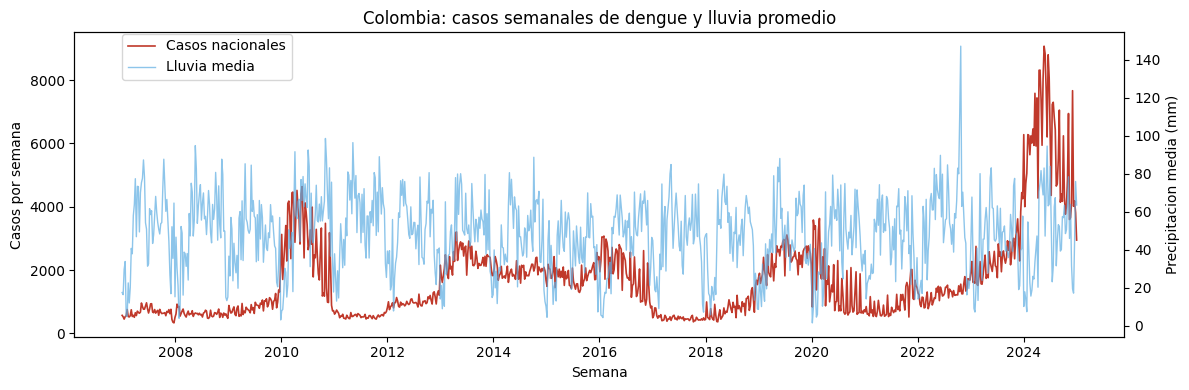

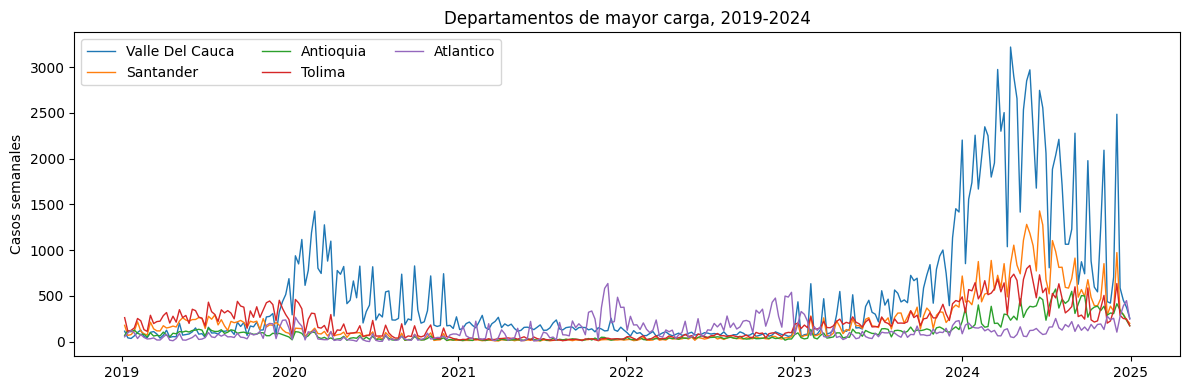

In [12]:
national = (
    train.groupby("semana_inicio", as_index=False)
    .agg(casos=("casos_dengue", "sum"), lluvia=("precip_chirps_mm", "mean"))
)
fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.plot(national.semana_inicio, national.casos, color="#C0392B", lw=1.2, label="Casos nacionales")
ax1.set_ylabel("Casos por semana")
ax2 = ax1.twinx()
ax2.plot(national.semana_inicio, national.lluvia, color="#5DADE2", alpha=0.7, lw=1, label="Lluvia media")
ax2.set_ylabel("Precipitacion media (mm)")
ax1.set_title("Colombia: casos semanales de dengue y lluvia promedio")
ax1.set_xlabel("Semana")
fig.legend(loc="upper left", bbox_to_anchor=(0.1, 0.92))
plt.tight_layout()
plt.show()

focus = ["Valle Del Cauca", "Santander", "Antioquia", "Tolima", "Atlantico"]
recent = train[train.anio.between(2019, 2024)]
fig, ax = plt.subplots(figsize=(12, 4))
for name in focus:
    part = recent[recent.departamento == name]
    ax.plot(part.semana_inicio, part.casos_dengue, lw=1, label=name)
ax.set_title("Departamentos de mayor carga, 2019-2024")
ax.set_ylabel("Casos semanales")
ax.legend(ncol=3)
plt.tight_layout()
plt.show()

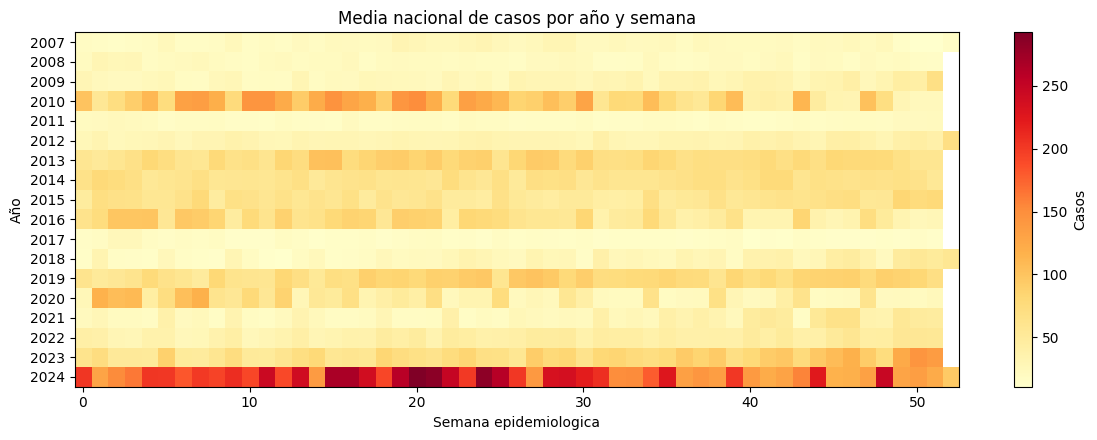

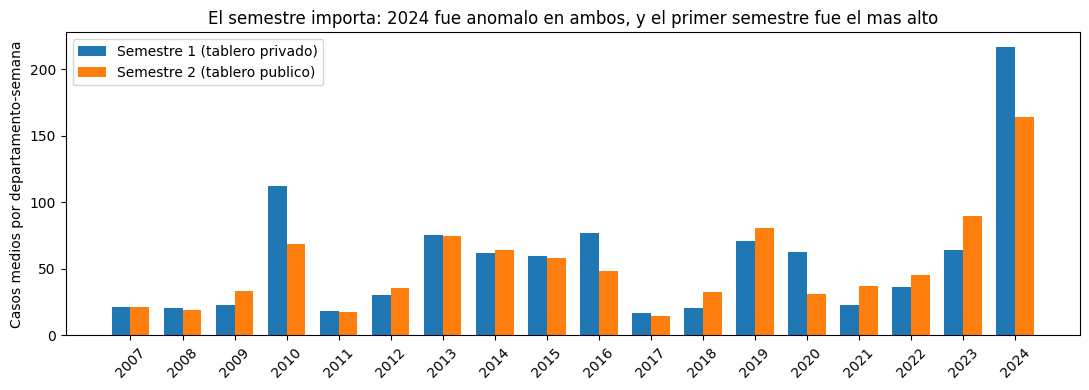

,semestre_1,semestre_2
anio,,
2019,70.8,81.0
2020,62.7,31.3
2021,22.7,37.2
2022,36.2,45.0
2023,64.3,90.0
2024,216.8,163.8


In [13]:
heat = train.pivot_table(index="anio", columns="semana", values="casos_dengue", aggfunc="mean")
fig, ax = plt.subplots(figsize=(12, 4.5))
image = ax.imshow(heat.to_numpy(), aspect="auto", cmap="YlOrRd")
ax.set_yticks(range(len(heat.index)))
ax.set_yticklabels(heat.index)
ax.set_xlabel("Semana epidemiologica")
ax.set_ylabel("Año")
ax.set_title("Media nacional de casos por año y semana")
fig.colorbar(image, ax=ax, label="Casos")
plt.tight_layout()
plt.show()

by_year = pd.DataFrame({
    "semestre_1": train[train.semana <= 26].groupby("anio").casos_dengue.mean(),
    "semestre_2": train[train.semana >= 27].groupby("anio").casos_dengue.mean(),
})
fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(by_year))
ax.bar(x - 0.18, by_year.semestre_1, width=0.36, label="Semestre 1 (tablero privado)")
ax.bar(x + 0.18, by_year.semestre_2, width=0.36, label="Semestre 2 (tablero publico)")
ax.set_xticks(x)
ax.set_xticklabels(by_year.index, rotation=45)
ax.set_ylabel("Casos medios por departamento-semana")
ax.set_title("El semestre importa: 2024 fue anomalo en ambos, y el primer semestre fue el mas alto")
ax.legend()
plt.tight_layout()
plt.show()
display(by_year.tail(6).round(1))

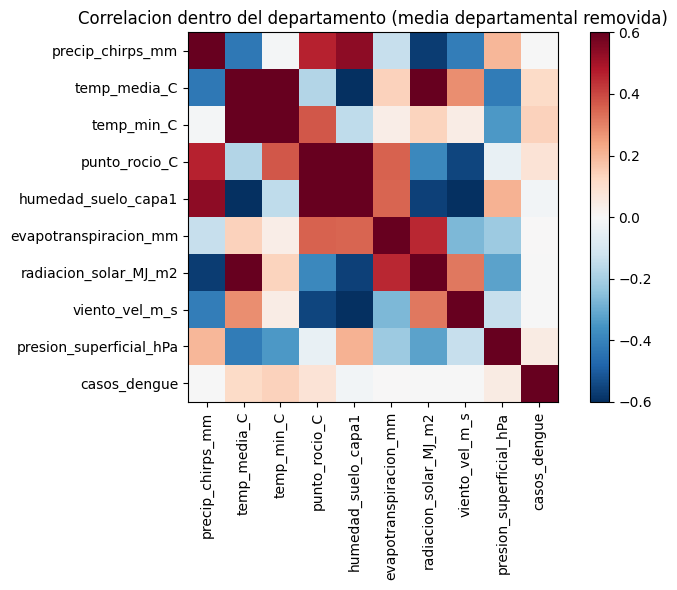

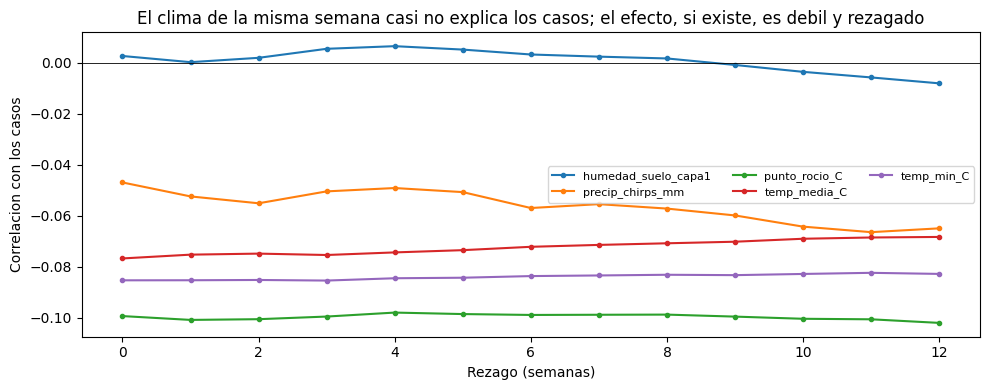

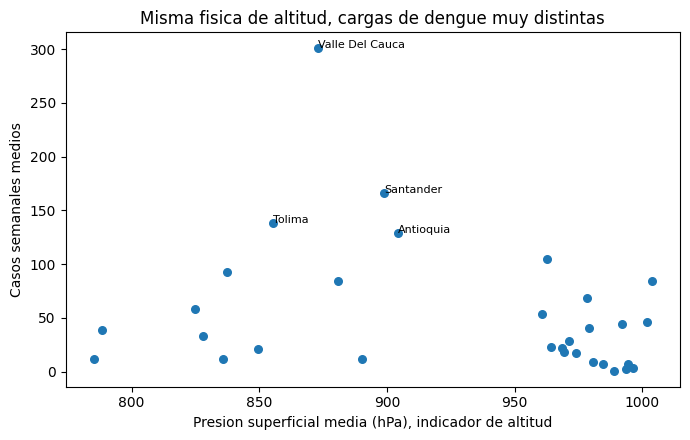

In [14]:
climate_cols = [
    "precip_chirps_mm", "temp_media_C", "temp_min_C", "punto_rocio_C",
    "humedad_suelo_capa1", "evapotranspiracion_mm", "radiacion_solar_MJ_m2",
    "viento_vel_m_s", "presion_superficial_hPa", "casos_dengue",
]
demeaned = train[climate_cols + ["id_departamento"]].copy()
for col in climate_cols:
    demeaned[col] = demeaned[col] - demeaned.groupby("id_departamento")[col].transform("mean")
corr = demeaned[climate_cols].corr()
fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(corr, cmap="RdBu_r", vmin=-0.6, vmax=0.6)
ax.set_xticks(range(len(corr)))
ax.set_yticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticklabels(corr.columns)
ax.set_title("Correlacion dentro del departamento (media departamental removida)")
fig.colorbar(image, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

def lagged_correlation(column, lag):
    pieces = []
    for _, group in train.groupby("id_departamento"):
        pieces.append(pd.DataFrame({"x": group[column].shift(lag), "y": group["casos_dengue"]}))
    pair = pd.concat(pieces, ignore_index=True).dropna()
    return float(pair.x.corr(pair.y))

lag_rows = []
for column in ["precip_chirps_mm", "temp_media_C", "temp_min_C", "humedad_suelo_capa1", "punto_rocio_C"]:
    for lag in range(0, 13):
        lag_rows.append({"variable": column, "rezago_semanas": lag, "correlacion": lagged_correlation(column, lag)})
lag_table = pd.DataFrame(lag_rows)
fig, ax = plt.subplots(figsize=(10, 4))
for variable, part in lag_table.groupby("variable"):
    ax.plot(part.rezago_semanas, part.correlacion, marker="o", ms=3, label=variable)
ax.axhline(0, color="black", lw=0.6)
ax.set_xlabel("Rezago (semanas)")
ax.set_ylabel("Correlacion con los casos")
ax.set_title("El clima de la misma semana casi no explica los casos; el efecto, si existe, es debil y rezagado")
ax.legend(ncol=3, fontsize=8)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(dept_level.presion, dept_level.media, s=30)
for _, row in dept_level.head(4).iterrows():
    ax.annotate(row.departamento, (row.presion, row.media), fontsize=8)
ax.set_xlabel("Presion superficial media (hPa), indicador de altitud")
ax.set_ylabel("Casos semanales medios")
ax.set_title("Misma fisica de altitud, cargas de dengue muy distintas")
plt.tight_layout()
plt.show()

### Lotes de reporte y el cierre de 2024

Dos hechos del final de 2024 cambian el pronóstico de 2025.

El primero es administrativo. Desde septiembre de 2024, la semana que contiene el primer miércoles de cada mes carga un lote de reporte. En el interior esa semana llega a 1,4-2,5 veces la media de su mes; en la Costa queda entre 0,4 y 0,7. El signo se repite en los cuatro meses, y el país ya había tenido episodios parecidos, a veces con otro calendario, en 2010, 2016, 2018, 2020 y 2021.

El segundo es epidemiológico. El nivel de diciembre de 2024 sin esos picos sigue muy por encima de cualquier cierre anterior, y el tablero privado empieza justo ahí.

,semana_lote_sobre_media_del_mes,minimo_4_meses,maximo_4_meses,nivel_sep_dic
departamento,,,,
Valle Del Cauca,2.18,1.88,2.55,1020.12
Santander,1.71,1.40,2.12,505.24
Bolivar,0.52,0.43,0.58,357.53
Antioquia,0.99,0.72,1.29,355.24
Tolima,1.71,1.58,1.80,338.59
Cundinamarca,1.39,1.23,1.56,228.76
Huila,2.48,2.01,2.79,210.29
Atlantico,0.61,0.34,0.77,208.88
Cordoba,0.67,0.57,0.78,178.35


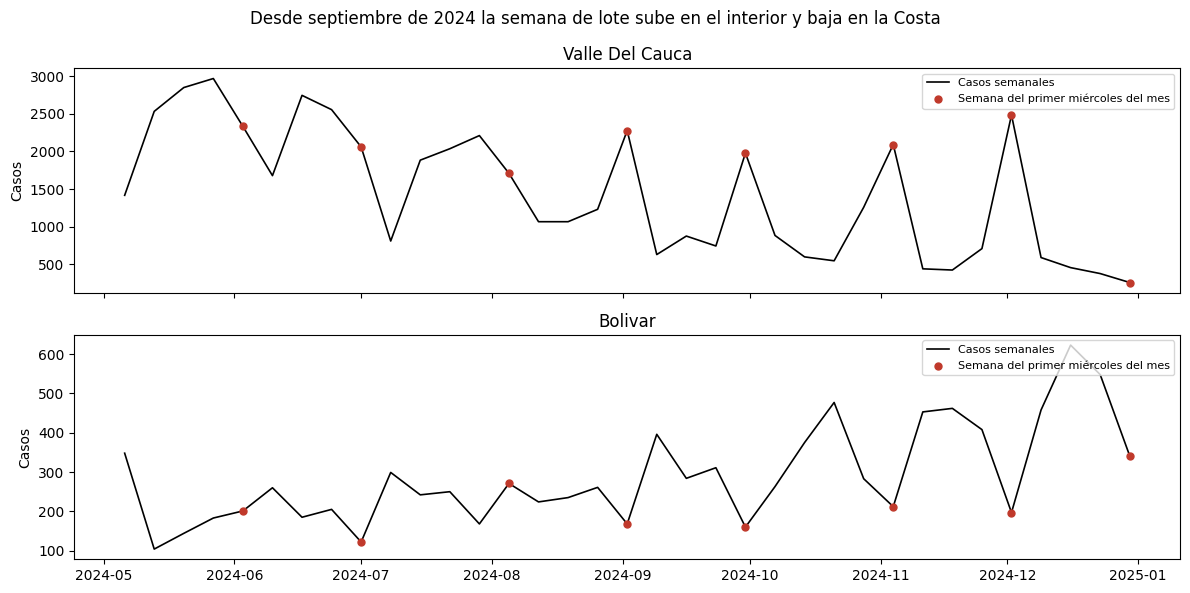

Cierre de cada año (mediana nacional de las semanas 45-52) y el año siguiente, como fracción de ese cierre


,cierre_sin_picos,pico_sobre_cierre,dic_sobre_oct,semanas_1_4,semanas_14_26,semanas_27_52
anio,,,,,,
2009,37.24,1.26,1.27,2.14,3.21,1.85
2010,31.66,4.05,0.65,0.69,0.57,0.55
2013,72.92,1.25,0.84,0.98,0.84,0.88
2015,70.60,1.03,1.24,1.18,1.06,0.69
2016,33.40,2.76,0.92,0.64,0.47,0.44
2019,86.02,1.07,1.12,1.04,0.53,0.36
2022,52.40,1.00,1.20,1.14,1.32,1.72
2023,111.79,1.07,1.52,1.45,2.18,1.49
2024,130.95,2.07,0.99,NaN,NaN,NaN


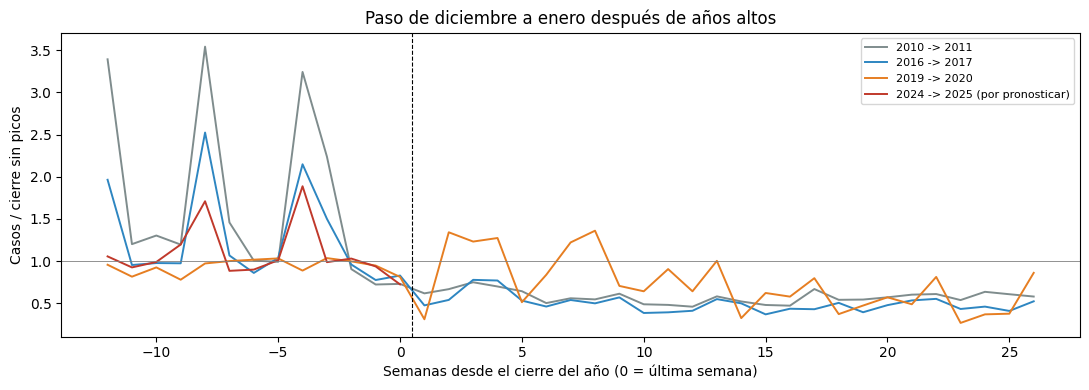

In [15]:
semanal = train.sort_values(["id_departamento", "semana_inicio"]).reset_index(drop=True)
miercoles = semanal.semana_inicio + pd.Timedelta(days=2)
semanal["mes"] = miercoles.dt.year * 100 + miercoles.dt.month
semanal["posicion_mes"] = semanal.groupby(["id_departamento", "mes"]).cumcount()
semanal["media_mes"] = semanal.groupby(["id_departamento", "mes"]).casos_dengue.transform("mean")

lotes_2024 = semanal[semanal.mes.between(202409, 202412) & (semanal.posicion_mes == 0)].copy()
lotes_2024["razon"] = lotes_2024.casos_dengue / lotes_2024.media_mes.replace(0, np.nan)
patron_eda = lotes_2024.groupby("departamento").razon.agg(["mean", "min", "max"])
patron_eda["nivel_sep_dic"] = semanal[semanal.mes.between(202409, 202412)].groupby("departamento").casos_dengue.mean()
display(
    patron_eda.sort_values("nivel_sep_dic", ascending=False)
    .head(12)
    .round(2)
    .rename(columns={"mean": "semana_lote_sobre_media_del_mes", "min": "minimo_4_meses", "max": "maximo_4_meses"})
)

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for ax, nombre in zip(axes, ["Valle Del Cauca", "Bolivar"]):
    parte = semanal[(semanal.departamento == nombre) & (semanal.semana_inicio >= "2024-05-01")]
    ax.plot(parte.semana_inicio, parte.casos_dengue, color="black", lw=1.2, label="Casos semanales")
    marcas = parte[parte.posicion_mes == 0]
    ax.scatter(marcas.semana_inicio, marcas.casos_dengue, color="#C0392B", zorder=3, s=25, label="Semana del primer miércoles del mes")
    ax.set_title(nombre)
    ax.set_ylabel("Casos")
    ax.legend(loc="upper right", fontsize=8)
fig.suptitle("Desde septiembre de 2024 la semana de lote sube en el interior y baja en la Costa")
plt.tight_layout()
plt.show()

nacional = train.groupby(["anio", "semana"]).casos_dengue.mean().unstack()
filas = []
for anio in range(2008, 2025):
    cierre = float(nacional.loc[anio, 45:52].median())
    fila = {
        "anio": anio,
        "cierre_sin_picos": cierre,
        "pico_sobre_cierre": float(nacional.loc[anio].dropna().rolling(4).mean().max()) / cierre,
        "dic_sobre_oct": float(nacional.loc[anio, 49:52].median() / nacional.loc[anio, 41:44].median()),
    }
    if anio + 1 in nacional.index:
        siguiente = nacional.loc[anio + 1]
        fila["semanas_1_4"] = float(siguiente.loc[1:4].mean()) / cierre
        fila["semanas_14_26"] = float(siguiente.loc[14:26].mean()) / cierre
        fila["semanas_27_52"] = float(siguiente.loc[27:52].mean()) / cierre
    filas.append(fila)
transiciones = pd.DataFrame(filas).set_index("anio")
print("Cierre de cada año (mediana nacional de las semanas 45-52) y el año siguiente, como fracción de ese cierre")
display(transiciones.loc[[2009, 2010, 2013, 2015, 2016, 2019, 2022, 2023, 2024]].round(2))

fig, ax = plt.subplots(figsize=(11, 4))
for anio, color in [(2010, "#7F8C8D"), (2016, "#2E86C1"), (2019, "#E67E22"), (2024, "#C0392B")]:
    cierre = transiciones.loc[anio, "cierre_sin_picos"]
    antes = nacional.loc[anio].dropna().iloc[-13:]
    x = list(range(-len(antes) + 1, 1))
    y = list(antes.to_numpy() / cierre)
    etiqueta = f"{anio} -> 2025 (por pronosticar)"
    if anio + 1 in nacional.index:
        x += list(range(1, 27))
        y += list(nacional.loc[anio + 1, 1:26].to_numpy() / cierre)
        etiqueta = f"{anio} -> {anio + 1}"
    ax.plot(x, y, color=color, lw=1.4, label=etiqueta)
ax.axvline(0.5, color="black", lw=0.8, ls="--")
ax.axhline(1.0, color="grey", lw=0.6)
ax.set_xlabel("Semanas desde el cierre del año (0 = última semana)")
ax.set_ylabel("Casos / cierre sin picos")
ax.set_title("Paso de diciembre a enero después de años altos")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Lectura para el modelado**

- La semana de lote es calendario: se sabe de antemano cuál es en 2025. Entra a las redes de la etapa 4 como una marca, y el nivel reciente de cada departamento se mide con la mediana de 8 semanas, que ignora esos picos.
- En 2010 y 2016 el cierre ya estaba lejos del pico (el pico de 4 semanas fue 4,1 y 2,8 veces el cierre). Las semanas 1 a 4 siguientes quedaron en 0,69 y 0,64 veces el cierre, y las semanas 14 a 26 en 0,57 y 0,47. En 2019 diciembre venía subiendo: enero de 2020 se quedó en el nivel del cierre (1,04) y la caída llegó en el segundo trimestre (0,53). 2024 cerró plano frente a octubre (0,99), como 2019, pero lejos de su pico (2,1 veces), como 2010 y 2016. Ese es el riesgo del tablero privado. La etapa 4 y la sección 6 lo tratan de frente.

## Lectura del analisis exploratorio y variables que si se pueden usar

Los picos nacionales de 2010, 2013, 2016, 2019 y sobre todo 2023-2024 no son un ciclo semanal suave. 2024 rompe la escala: la media del primer semestre fue cerca de 217 casos por departamento-semana y la del segundo cerca de 164, frente a una historia previa mucho mas baja. Ese quiebre importa dos veces. El tablero privado mira enero-junio de 2025, justo el semestre que en 2024 fue el peor, y el publico mira julio-diciembre. Un modelo calibrado solo con el promedio 2007-2023 va a subestimar si el regimen alto continua, y uno que copie 2024 semana a semana va a fallar si 2025 revierte.

Dentro de cada departamento la correlacion lineal del clima con los casos es debil. Tiene sentido biologico: el *Aedes aegypti* responde a lluvia y temperatura con varias semanas de rezago (huevo, larva, adulto, incubacion), y ademas la presion y la temperatura absoluta identifican la altitud del departamento mas que el brote de esa semana. La presion de Vaupes y la de Quindio dicen donde queda el territorio, no cuantos casos vendran el martes.

Por eso las redes no reciben el conteo de la semana que deben predecir. Reciben tres bloques, todos conocidos antes de cerrar la semana objetivo o directamente publicados en `test.parquet`:

1. **Clima exogeno de la ventana**, incluida la semana a pronosticar, porque el archivo de 2025 trae esas columnas. En la segunda etapa se agregan anomalias contra el clima normal de ese departamento y esa semana, y medias moviles de 4 semanas de lluvia, temperatura y humedad.
2. **Calendario.** Seno y coseno de la semana epidemiologica, para no tratar la semana 52 y la 1 como numeros lejanos. La direccion del viento pasa al mismo formato circular en la etapa 2: 0 y 360 grados son el mismo viento.
3. **Memoria epidemiologica anterior al año del pronostico.** Media historica del departamento, anclas de las ultimas 8 y 26 semanas del año previo, casos de la misma semana un año atras, perfil estacional y la forma `ancla_26 * perfil_estacional / media_historica`. Nada de esto usa casos del año que se esta prediciendo.

La media historica es la variable que el codigo base no tenia. Sin ella, dos departamentos con clima parecido y poblaciones distintas producen el mismo pronostico. El MSE de la competencia no perdona ese error en Valle del Cauca.

## Preparacion sin fuga y forma de los tensores

El corte de validacion de las fases 2 a 5 es 2024 completo: se entrena con años anteriores y se evaluan las 53 semanas de 2024. El escalador se ajusta solo con filas de entrenamiento.

La ventana de longitud L termina en la semana objetivo e incluye clima y calendario de esa semana. No incluye `casos_dengue`. Para puntuar la semana 1 de 2024, la ventana se apoya en las ultimas semanas de 2023; por eso el conjunto de validacion se construye sobre la serie completa y no sobre un recorte que empiece el 1 de enero.

Organizacion por arquitectura, que es distinta aunque la tabla de ejemplos sea la misma:

- **MLP.** La ventana se aplana a un vector `(lote, longitud por numero de variables)`. Una capa densa no tiene eje temporal; el orden queda grabado en la posicion del vector.
- **RNN, LSTM y GRU.** El tensor queda en `(lote, longitud, numero de variables)`. La celda recorre el tiempo y la capa final lee solo el ultimo estado oculto.
- **TCN.** Entra el mismo tensor 3D, se transpone a `(lote, numero de variables, longitud)` para la convolucion de una dimension y el relleno causal se pone solo a la izquierda. La salida usa el ultimo paso de tiempo. Asi la prediccion de la semana t no ve el clima de t+1.

In [16]:
features = build_features(train)
assert_no_year_leak(features, train)
COLS_STAGE1 = stage1_columns()
COLS_STAGE2 = stage2_columns()
print("Filas con historia suficiente:", features.shape)
print("Variables de la etapa 1:", len(COLS_STAGE1), COLS_STAGE1)
print("Variables de la etapa 2:", len(COLS_STAGE2))
print("Nulos etapa 2:", int(features[COLS_STAGE2].isna().sum().sum()))

scaled_demo, _ = scale_features(features, COLS_STAGE1, features.anio < VAL_YEAR)
demo = WindowDataset(scaled_demo, COLS_STAGE1, seq_len=8, target_years={2024}, residual=False)
x0, y0, y_raw0, shape0, id0, week0, dept0 = demo[0]
print("Ejemplo de validacion", id0, dept0, "semana", week0)
print("MLP / RNN ven X con forma", tuple(x0.shape), "-> MLP lo aplana a", int(np.prod(x0.shape)))
print("y (casos) =", float(y_raw0), "| el objetivo no esta dentro de la entrada")
print("Ventanas de entrenamiento < 2024:", len(WindowDataset(scaled_demo, COLS_STAGE1, 8, set(range(2008, 2024)), False)))
print("Ventanas de validacion 2024:", len(demo))

Filas con historia suficiente: (27497, 50)
Variables de la etapa 1: 14 ['precip_chirps_mm', 'temp_media_C', 'temp_max_C', 'temp_min_C', 'punto_rocio_C', 'humedad_suelo_capa1', 'evapotranspiracion_mm', 'radiacion_solar_MJ_m2', 'viento_vel_m_s', 'viento_dir_grados', 'presion_superficial_hPa', 'week_sin', 'week_cos', 'log_dmean']
Variables de la etapa 2: 35
Nulos etapa 2: 0
Ejemplo de validacion 1_2024_1 Amazonas semana 1
MLP / RNN ven X con forma (8, 14) -> MLP lo aplana a 112
y (casos) = 17.0 | el objetivo no esta dentro de la entrada


Ventanas de entrenamiento < 2024: 25637
Ventanas de validacion 2024: 1643


In [17]:
def plot_histories(names, title):
    fig, ax = plt.subplots(figsize=(8, 4))
    for name in names:
        history = HISTORIES.get(name)
        if not history:
            continue
        ax.plot([row["epoch"] for row in history], [row["val_mse"] for row in history], marker="o", ms=3, label=name)
    ax.set_xlabel("Epoca")
    ax.set_ylabel("MSE de validacion 2024")
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


def show_models(names):
    table = pd.DataFrame(RESULTS)
    table = table[table.modelo.isin(names)].set_index("modelo")
    columns = ["familia", "etapa", "seq_len", "n_params", "epochs_ran", "val_mse", "val_rmse", "val_mae", "val_r2", "mse_h1", "mse_h2"]
    display(table[columns].rename(columns={"seq_len": "longitud", "n_params": "parametros", "epochs_ran": "epocas", "val_mse": "mse_validacion", "val_rmse": "raiz_mse", "val_mae": "mae_validacion", "val_r2": "r2_validacion", "mse_h1": "mse_semestre_1", "mse_h2": "mse_semestre_2"}).round(3))


def compare_pair(base_name, opt_name):
    table = pd.DataFrame(RESULTS).set_index("modelo")
    base, opt = table.loc[base_name], table.loc[opt_name]
    if pd.isna(base.val_mse) or pd.isna(opt.val_mse):
        print(f"No se compara {base_name} contra {opt_name} porque un entrenamiento no termino.")
        return
    delta = float(opt.val_mse - base.val_mse)
    direction = "reduce" if delta < 0 else "aumenta"
    print(
        f"{opt_name} {direction} el MSE de 2024 frente a {base_name}: "
        f"{base.val_mse:.0f} -> {opt.val_mse:.0f} ({delta:+.0f}). "
        f"Semestre 1: {base.mse_h1:.0f} -> {opt.mse_h1:.0f}. "
        f"Semestre 2: {base.mse_h2:.0f} -> {opt.mse_h2:.0f}."
    )
    if delta > 0:
        print("Mas capacidad no corrigio el error. El limite esta en las variables y en el cambio de regimen, no en el numero de capas.")
    else:
        print("La arquitectura nueva aprovecha mejor la misma ventana. El cambio no es cosmetico: mueve el MSE que la rubrica pide optimizar.")

### Corrida de un experimento

Cada corrida entrena con los años anteriores a 2024, mide 2024 y guarda el historial. Si una red no termina, la tabla sigue y esa fila queda vacia.

In [18]:
def run_experiment(name, family, stage, factory, columns, seq_len, residual, train_kwargs, frame, epochs, patience):
    print(f"\n=== {name} | longitud={seq_len} | residual={residual} | variables={len(columns)} ===")
    try:
        n_params = count_parameters(factory())
        reset_seed(42)
        fit_mask = frame["anio"] < VAL_YEAR
        scaled, _scaler = scale_features(frame, columns, fit_mask)
        train_years = {int(year) for year in frame.loc[fit_mask, "anio"].unique()}
        train_ds = WindowDataset(scaled, columns, seq_len, train_years, residual)
        val_ds = WindowDataset(scaled, columns, seq_len, {VAL_YEAR}, residual)
        print(f"ventanas de entrenamiento={len(train_ds)} validacion={len(val_ds)} parametros={n_params}")
        model, history, _scores = train_forecaster(
            factory(),
            make_loader(train_ds, BATCH_SIZE, True),
            make_loader(val_ds, BATCH_SIZE, False),
            DEVICE,
            residual,
            epochs=epochs,
            patience=patience,
            **train_kwargs,
        )
        preds = collect_predictions(model, make_loader(val_ds, BATCH_SIZE, False), DEVICE, residual)
        scores = regression_scores(preds)
        epochs_ran = len(history)
        HISTORIES[name] = history
        PREDICTIONS[name] = preds
    except Exception as exc:
        print(f"FALLO {name}: {type(exc).__name__}: {exc}")
        n_params = 0
        epochs_ran = 0
        scores = {"val_mse": np.nan, "val_rmse": np.nan, "val_mae": np.nan, "val_r2": np.nan, "mse_h1": np.nan, "mse_h2": np.nan}
    SPECS[name] = {
        "name": name,
        "family": family,
        "stage": stage,
        "factory": factory,
        "columns": columns,
        "seq_len": seq_len,
        "residual": residual,
        "train_kwargs": train_kwargs,
    }
    RESULTS.append({
        "modelo": name,
        "familia": family,
        "etapa": stage,
        "seq_len": seq_len,
        "residual": residual,
        "n_features": len(columns),
        "n_params": n_params,
        "epochs_ran": epochs_ran,
        **scores,
    })
    return scores

## 2. Perceptron multicapa

El MLP del codigo base es una capa de 64 unidades, ReLU, otra capa lineal y un ReLU final que anula el gradiente cuando la prediccion cae a cero. Entrena con Adam a 0.001, MSE, ventana de 5 semanas y lotes de 32, y no sabe que departamento esta viendo.

Aqui las dos variantes comparten las variables de la etapa 1 (clima, calendario y log de la media historica del departamento) y el mismo corte 2024. El tamano de lote pasa a 256 en todas las redes: con 24 mil ventanas, 32 ejemplos por paso alarga el entrenamiento y no es la pregunta de arquitectura. Los cambios que si se comparan, de la variante base a la optimizada, son estos cuatro (en realidad seis):

| Hiperparametro | Variante base | Variante optimizada |
| --- | --- | --- |
| Capas ocultas | 64 | 128, 64, 32 |
| Activacion | ReLU, tambien en la salida | GELU y salida lineal |
| Regularizacion | ninguna | abandono 0.2 y normalizacion por lote y AdamW con decaimiento de pesos 1e-4 |
| Ventana, tasa y planificador | ventana de 8, tasa=0.001, sin planificador | ventana de 16, tasa=0.0005, reduccion de la tasa si la validacion se estanca |

La salida lineal es deliberada. El ReLU final del codigo base impide predecir cero con gradiente y aplasta brotes pequenos.


=== MLP base | longitud=8 | residual=False | variables=14 ===


ventanas de entrenamiento=25637 validacion=1643 parametros=7297


  epoca 01 | entrenamiento 9350.9 | validacion 155654.1 | semestre 1 220033.2 | semestre 2 93659.5


  epoca 02 | entrenamiento 7961.9 | validacion 145957.2 | semestre 1 208259.5 | semestre 2 85962.4


  epoca 03 | entrenamiento 6770.8 | validacion 136771.0 | semestre 1 196434.7 | semestre 2 79317.1


  epoca 04 | entrenamiento 5828.2 | validacion 127324.1 | semestre 1 184108.5 | semestre 2 72642.7


... (27 outputs left out)

  epoca 15 | entrenamiento 7722.7 | validacion 143490.7 | semestre 1 202886.2 | semestre 2 86295.0


  epoca 16 | entrenamiento 7563.2 | validacion 144845.5 | semestre 1 204501.7 | semestre 2 87398.7


,familia,etapa,longitud,parametros,epocas,mse_validacion,raiz_mse,mae_validacion,r2_validacion,mse_semestre_1,mse_semestre_2
modelo,,,,,,,,,,,
MLP base,MLP,1,8,7297,16,117530.836,342.828,134.273,0.071,170463.922,66558.242
MLP optimizado,MLP,1,16,39617,16,143490.656,378.802,172.428,-0.135,202886.172,86294.961


MLP optimizado aumenta el MSE de 2024 frente a MLP base: 117531 -> 143491 (+25960). Semestre 1: 170464 -> 202886. Semestre 2: 66558 -> 86295.
Mas capacidad no corrigio el error. El limite esta en las variables y en el cambio de regimen, no en el numero de capas.


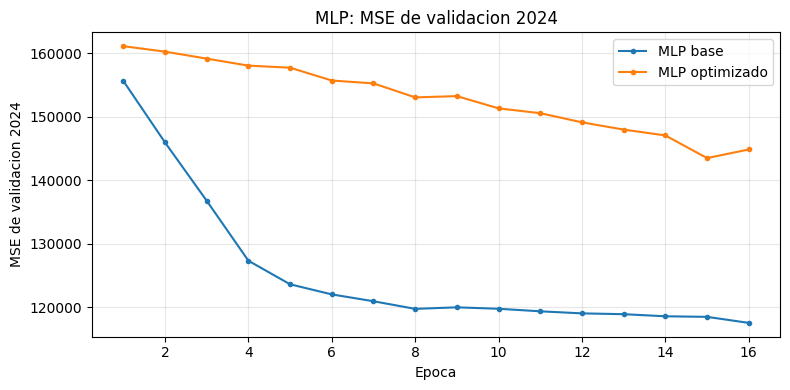

In [19]:
mlp_base_kwargs = dict(lr=1e-3, weight_decay=0.0, use_scheduler=False, optimizer_name="adam")
mlp_opt_kwargs = dict(lr=5e-4, weight_decay=1e-4, use_scheduler=True, optimizer_name="adamw")

run_experiment(
    "MLP base", "MLP", 1,
    lambda: MLPForecaster(len(COLS_STAGE1), 8, (64,), 0.0, "relu", False, True),
    COLS_STAGE1, 8, False, mlp_base_kwargs, features, RUBRIC_EPOCHS, RUBRIC_PATIENCE,
)
run_experiment(
    "MLP optimizado", "MLP", 1,
    lambda: MLPForecaster(len(COLS_STAGE1), 16, (128, 64, 32), 0.2, "gelu", True, False),
    COLS_STAGE1, 16, False, mlp_opt_kwargs, features, RUBRIC_EPOCHS, RUBRIC_PATIENCE,
)
show_models(["MLP base", "MLP optimizado"])
compare_pair("MLP base", "MLP optimizado")
plot_histories(["MLP base", "MLP optimizado"], "MLP: MSE de validacion 2024")

## 3. RNN simple

La RNN del curso (`RNNModel`) recorre la ventana y proyecta el ultimo estado con una capa lineal. No tiene compuertas, asi que alargar la memoria compite con el desvanecimiento del gradiente. Por eso la variante optimizada no solo agranda la red: cambia la no linealidad, apila una segunda capa con abandono y acorta el paso de Adam. El recorte de gradiente a norma 1 va en las dos variantes; sin eso la RNN con ReLU diverge con conteos de cientos de casos.

| Hiperparametro | Variante base | Variante optimizada |
| --- | --- | --- |
| tamano oculto | 32 | 96 |
| numero de capas | 1 | 2 |
| no linealidad y abandono | tangente hiperbolica, sin abandono | ReLU, abandono 0.2 y cabeza densa de 32 |
| Ventana y optimizador | ventana de 8, Adam 1e-3 | ventana de 16, AdamW 5e-4 con planificador |


=== RNN base | longitud=8 | residual=False | variables=14 ===


ventanas de entrenamiento=25637 validacion=1643 parametros=1569


  epoca 01 | entrenamiento 9674.4 | validacion 160609.2 | semestre 1 225833.2 | semestre 2 97800.8


  epoca 02 | entrenamiento 9303.2 | validacion 159269.7 | semestre 1 224296.2 | semestre 2 96651.5


  epoca 03 | entrenamiento 9022.6 | validacion 158019.6 | semestre 1 222857.8 | semestre 2 95582.8


  epoca 04 | entrenamiento 8776.5 | validacion 156813.9 | semestre 1 221467.0 | semestre 2 94555.3


... (24 outputs left out)

  epoca 12 | entrenamiento 3979.8 | validacion 91494.4 | semestre 1 134516.8 | semestre 2 50065.3


  epoca 13 | entrenamiento 3745.9 | validacion 89178.5 | semestre 1 131136.2 | semestre 2 48774.9
  parada temprana en la epoca 13


,familia,etapa,longitud,parametros,epocas,mse_validacion,raiz_mse,mae_validacion,r2_validacion,mse_semestre_1,mse_semestre_2
modelo,,,,,,,,,,,
RNN base,RNN,1,8,1569,16,147342.922,383.853,160.781,-0.165,210334.391,86684.492
RNN optimizada,RNN,1,16,32513,13,87527.375,295.850,112.200,0.308,129215.734,47383.016


RNN optimizada reduce el MSE de 2024 frente a RNN base: 147343 -> 87527 (-59816). Semestre 1: 210334 -> 129216. Semestre 2: 86684 -> 47383.
La arquitectura nueva aprovecha mejor la misma ventana. El cambio no es cosmetico: mueve el MSE que la rubrica pide optimizar.


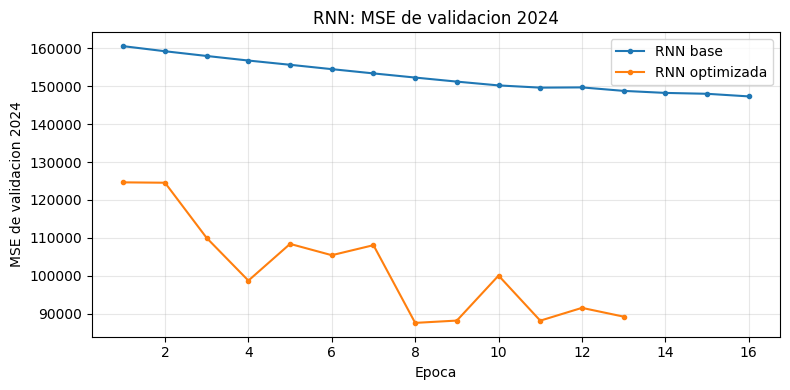

In [20]:
rnn_base_kwargs = dict(lr=1e-3, weight_decay=0.0, use_scheduler=False, optimizer_name="adam")
rnn_opt_kwargs = dict(lr=5e-4, weight_decay=1e-4, use_scheduler=True, optimizer_name="adamw")

run_experiment(
    "RNN base", "RNN", 1,
    lambda: RecurrentForecaster("rnn", len(COLS_STAGE1), 32, 1, 0.0, nonlinearity="tanh", head_hidden=0),
    COLS_STAGE1, 8, False, rnn_base_kwargs, features, RUBRIC_EPOCHS, RUBRIC_PATIENCE,
)
run_experiment(
    "RNN optimizada", "RNN", 1,
    lambda: RecurrentForecaster("rnn", len(COLS_STAGE1), 96, 2, 0.2, nonlinearity="relu", head_hidden=32),
    COLS_STAGE1, 16, False, rnn_opt_kwargs, features, RUBRIC_EPOCHS, RUBRIC_PATIENCE,
)
show_models(["RNN base", "RNN optimizada"])
compare_pair("RNN base", "RNN optimizada")
plot_histories(["RNN base", "RNN optimizada"], "RNN: MSE de validacion 2024")

## 4. LSTM y GRU

LSTM y GRU resuelven el mismo problema de memoria con distintas compuertas. LSTM mantiene un estado de celda aparte del estado oculto; GRU mezcla memoria y estado en menos parametros. El codigo base de la competencia no trae ninguna de las dos. La referencia de clase es una sola capa pequena. Aqui se entrenan las dos familias, cada una en version corta y version modificada, sobre las mismas variables de la etapa 1.

Cambios de la version base a la optimizada, en cada familia (son mas de cuatro):

| Hiperparametro | Base LSTM / GRU | LSTM optimizada | GRU optimizada |
| --- | --- | --- | --- |
| Tipo de celda | LSTM o GRU de 1 capa | LSTM | GRU |
| tamano oculto | 32 | 128 | 96 |
| numero de capas | 1 | 2 | 2 |
| Abandono y cabeza | sin abandono, cabeza lineal | abandono 0.3, cabeza 64 | abandono 0.2, cabeza 64 |
| Ventana y optimizador | ventana de 8, Adam 1e-3 | ventana de 16, AdamW 5e-4 y planificador | ventana de 12, AdamW 5e-4 y planificador |

En la libreria el abandono de la celda recurrente solo actua si hay al menos dos capas. Subir el abandono sin apilar capas no cambiaria nada; por eso `numero de capas` y el abandono se mueven juntos.


=== LSTM base | longitud=8 | residual=False | variables=14 ===


ventanas de entrenamiento=25637 validacion=1643 parametros=6177


  epoca 01 | entrenamiento 9730.5 | validacion 160425.3 | semestre 1 225619.0 | semestre 2 97646.2


  epoca 02 | entrenamiento 9237.1 | validacion 158933.7 | semestre 1 223910.0 | semestre 2 96364.0


  epoca 03 | entrenamiento 8942.1 | validacion 157655.7 | semestre 1 222440.3 | semestre 2 95270.6


  epoca 04 | entrenamiento 8685.0 | validacion 156435.9 | semestre 1 221033.1 | semestre 2 94231.3


... (61 outputs left out)

  epoca 15 | entrenamiento 4317.4 | validacion 114181.9 | semestre 1 166226.4 | semestre 2 64064.9


  epoca 16 | entrenamiento 4318.9 | validacion 111061.2 | semestre 1 161778.8 | semestre 2 62222.1


,familia,etapa,longitud,parametros,epocas,mse_validacion,raiz_mse,mae_validacion,r2_validacion,mse_semestre_1,mse_semestre_2
modelo,,,,,,,,,,,
LSTM base,LSTM,1,8,6177,16,147181.719,383.643,159.833,-0.164,210040.750,86650.789
LSTM optimizada,LSTM,1,16,214145,16,108235.539,328.992,123.633,0.144,160522.656,57884.980
GRU base,GRU,1,8,4641,16,147121.078,383.564,159.441,-0.163,210043.328,86529.258
GRU optimizada,GRU,1,12,94401,16,111061.227,333.258,121.477,0.122,161778.797,62222.109


LSTM optimizada reduce el MSE de 2024 frente a LSTM base: 147182 -> 108236 (-38946). Semestre 1: 210041 -> 160523. Semestre 2: 86651 -> 57885.
La arquitectura nueva aprovecha mejor la misma ventana. El cambio no es cosmetico: mueve el MSE que la rubrica pide optimizar.
GRU optimizada reduce el MSE de 2024 frente a GRU base: 147121 -> 111061 (-36060). Semestre 1: 210043 -> 161779. Semestre 2: 86529 -> 62222.
La arquitectura nueva aprovecha mejor la misma ventana. El cambio no es cosmetico: mueve el MSE que la rubrica pide optimizar.


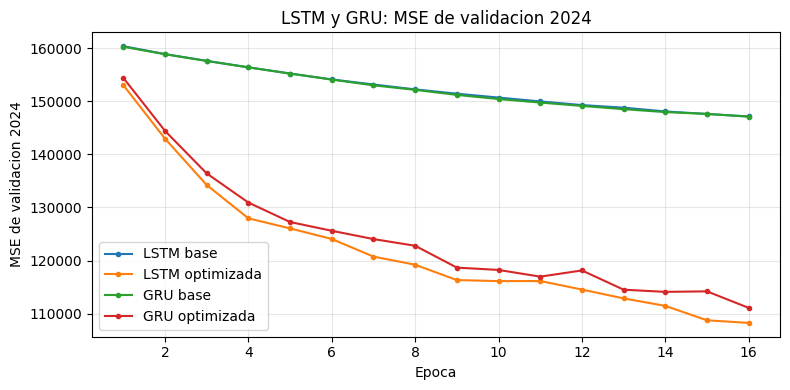

In [21]:
rec_base_kwargs = dict(lr=1e-3, weight_decay=0.0, use_scheduler=False, optimizer_name="adam")
rec_opt_kwargs = dict(lr=5e-4, weight_decay=1e-4, use_scheduler=True, optimizer_name="adamw")

run_experiment(
    "LSTM base", "LSTM", 1,
    lambda: RecurrentForecaster("lstm", len(COLS_STAGE1), 32, 1, 0.0, head_hidden=0),
    COLS_STAGE1, 8, False, rec_base_kwargs, features, RUBRIC_EPOCHS, RUBRIC_PATIENCE,
)
run_experiment(
    "LSTM optimizada", "LSTM", 1,
    lambda: RecurrentForecaster("lstm", len(COLS_STAGE1), 128, 2, 0.3, head_hidden=64),
    COLS_STAGE1, 16, False, rec_opt_kwargs, features, RUBRIC_EPOCHS, RUBRIC_PATIENCE,
)
run_experiment(
    "GRU base", "GRU", 1,
    lambda: RecurrentForecaster("gru", len(COLS_STAGE1), 32, 1, 0.0, head_hidden=0),
    COLS_STAGE1, 8, False, rec_base_kwargs, features, RUBRIC_EPOCHS, RUBRIC_PATIENCE,
)
run_experiment(
    "GRU optimizada", "GRU", 1,
    lambda: RecurrentForecaster("gru", len(COLS_STAGE1), 96, 2, 0.2, head_hidden=64),
    COLS_STAGE1, 12, False, rec_opt_kwargs, features, RUBRIC_EPOCHS, RUBRIC_PATIENCE,
)
show_models(["LSTM base", "LSTM optimizada", "GRU base", "GRU optimizada"])
compare_pair("LSTM base", "LSTM optimizada")
compare_pair("GRU base", "GRU optimizada")
plot_histories(
    ["LSTM base", "LSTM optimizada", "GRU base", "GRU optimizada"],
    "LSTM y GRU: MSE de validacion 2024",
)

## 5. TCN

El TCN del codigo base usa cuatro bloques residuales, filtro de tamano 3, abandono 0.1, normalizacion por grupos con un solo grupo y canales `[32, 32, 64, 64]`. Cada bloque tiene dos convoluciones causales con dilatacion `2^i`. El campo receptivo queda

`R = 1 + 2 * (filtro - 1) * (2^bloques - 1)`.

Con filtro de tamano 3 y 4 bloques, R = 61 pasos: mas largo que la ventana de 8, asi que parte del filtro mira ceros de relleno. La variante optimizada acorta la profundidad, agranda el filtro y alarga la ventana para que el campo y los datos se parezcan.

| Hiperparametro | TCN base (codigo de la competencia) | TCN optimizada |
| --- | --- | --- |
| Canales / bloques | 32, 32, 64, 64 (4 bloques, R=61) | 32, 32, 64 (3 bloques) |
| Tamano del filtro | 3 | 5 (R=57) |
| Abandono, activacion y norma | 0.1, ReLU, normalizacion por grupos, 1 grupo | 0.25, GELU, normalizacion por grupos, 4 grupos |
| Ventana y optimizador | ventana de 8, Adam 1e-3 | ventana de 20, AdamW 5e-4, decaimiento de pesos 1e-4 y planificador |

Campo receptivo base: 61
Campo receptivo optimizado: 57

=== TCN base | longitud=8 | residual=False | variables=14 ===


ventanas de entrenamiento=25637 validacion=1643 parametros=57377


  epoca 01 | entrenamiento 7178.9 | validacion 133209.9 | semestre 1 192919.2 | semestre 2 75712.0


  epoca 02 | entrenamiento 5343.5 | validacion 126503.2 | semestre 1 183034.8 | semestre 2 72065.4


  epoca 03 | entrenamiento 5012.6 | validacion 118340.9 | semestre 1 171700.4 | semestre 2 66957.7


  epoca 04 | entrenamiento 4778.6 | validacion 117479.2 | semestre 1 170093.4 | semestre 2 66813.7


... (27 outputs left out)

  epoca 15 | entrenamiento 3492.5 | validacion 97638.6 | semestre 1 139360.4 | semestre 2 57462.0


  epoca 16 | entrenamiento 3454.6 | validacion 94121.3 | semestre 1 137691.0 | semestre 2 52165.4


,familia,etapa,longitud,parametros,epocas,mse_validacion,raiz_mse,mae_validacion,r2_validacion,mse_semestre_1,mse_semestre_2
modelo,,,,,,,,,,,
TCN base,TCN,1,8,57377,16,95672.242,309.309,125.026,0.244,133367.844,59372.762
TCN optimizada,TCN,1,20,51745,16,94121.328,306.792,119.390,0.256,137690.953,52165.391


TCN optimizada reduce el MSE de 2024 frente a TCN base: 95672 -> 94121 (-1551). Semestre 1: 133368 -> 137691. Semestre 2: 59373 -> 52165.
La arquitectura nueva aprovecha mejor la misma ventana. El cambio no es cosmetico: mueve el MSE que la rubrica pide optimizar.


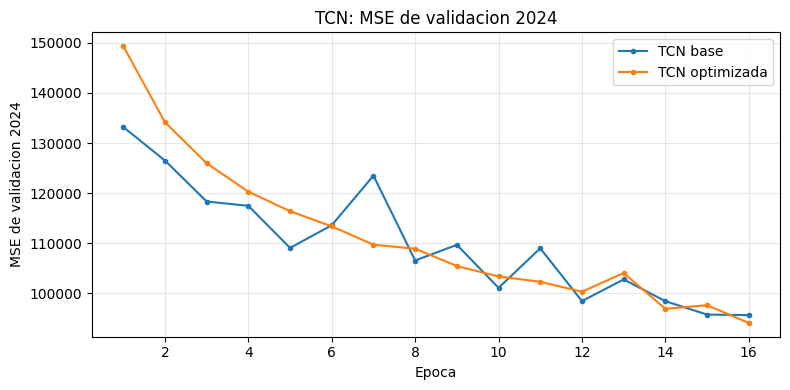

In [22]:
print("Campo receptivo base:", 1 + 2 * (3 - 1) * (2 ** 4 - 1))
print("Campo receptivo optimizado:", 1 + 2 * (5 - 1) * (2 ** 3 - 1))

tcn_base_kwargs = dict(lr=1e-3, weight_decay=0.0, use_scheduler=False, optimizer_name="adam")
tcn_opt_kwargs = dict(lr=5e-4, weight_decay=1e-4, use_scheduler=True, optimizer_name="adamw")

run_experiment(
    "TCN base", "TCN", 1,
    lambda: TCNForecaster(len(COLS_STAGE1), (32, 32, 64, 64), 3, 0.1, 1, "relu"),
    COLS_STAGE1, 8, False, tcn_base_kwargs, features, RUBRIC_EPOCHS, RUBRIC_PATIENCE,
)
run_experiment(
    "TCN optimizada", "TCN", 1,
    lambda: TCNForecaster(len(COLS_STAGE1), (32, 32, 64), 5, 0.25, 4, "gelu"),
    COLS_STAGE1, 20, False, tcn_opt_kwargs, features, RUBRIC_EPOCHS, RUBRIC_PATIENCE,
)
show_models(["TCN base", "TCN optimizada"])
compare_pair("TCN base", "TCN optimizada")
plot_histories(["TCN base", "TCN optimizada"], "TCN: MSE de validacion 2024")

## Comparacion de la etapa 1

Todas las redes de arriba responden la misma pregunta: dado el clima reciente, el calendario y el nivel historico del departamento, cual es el conteo de la semana. Ninguna ve los casos de 2024 durante el entrenamiento. La referencia epidemiologica de esta tabla no es una red: es la forma `ancla de 26 semanas de 2023 * perfil estacional / media historica`. Sirve para saber si la red esta aprendiendo algo que esa regla no diga ya.

,modelo,familia,etapa,mse_validacion,mae_validacion,r2_validacion,mse_semestre_1,mse_semestre_2,parametros
10,Forma estacional escalada,Referencia,0,76519.082,115.136,0.395,112001.800,42350.540,0
3,RNN optimizada,RNN,1,87527.375,112.200,0.308,129215.734,47383.016,32513
9,TCN optimizada,TCN,1,94121.328,119.390,0.256,137690.953,52165.391,51745
8,TCN base,TCN,1,95672.242,125.026,0.244,133367.844,59372.762,57377
5,LSTM optimizada,LSTM,1,108235.539,123.633,0.144,160522.656,57884.980,214145
7,GRU optimizada,GRU,1,111061.227,121.477,0.122,161778.797,62222.109,94401
11,Misma semana del año anterior,Referencia,0,117021.758,138.334,0.075,180038.258,56339.203,0
0,MLP base,MLP,1,117530.836,134.273,0.071,170463.922,66558.242,7297
12,Perfil estacional historico,Referencia,0,122123.779,144.917,0.034,176427.151,69831.642,0
1,MLP optimizado,MLP,1,143490.656,172.428,-0.135,202886.172,86294.961,39617


Mejor red de la etapa 1 en 2024: RNN optimizada


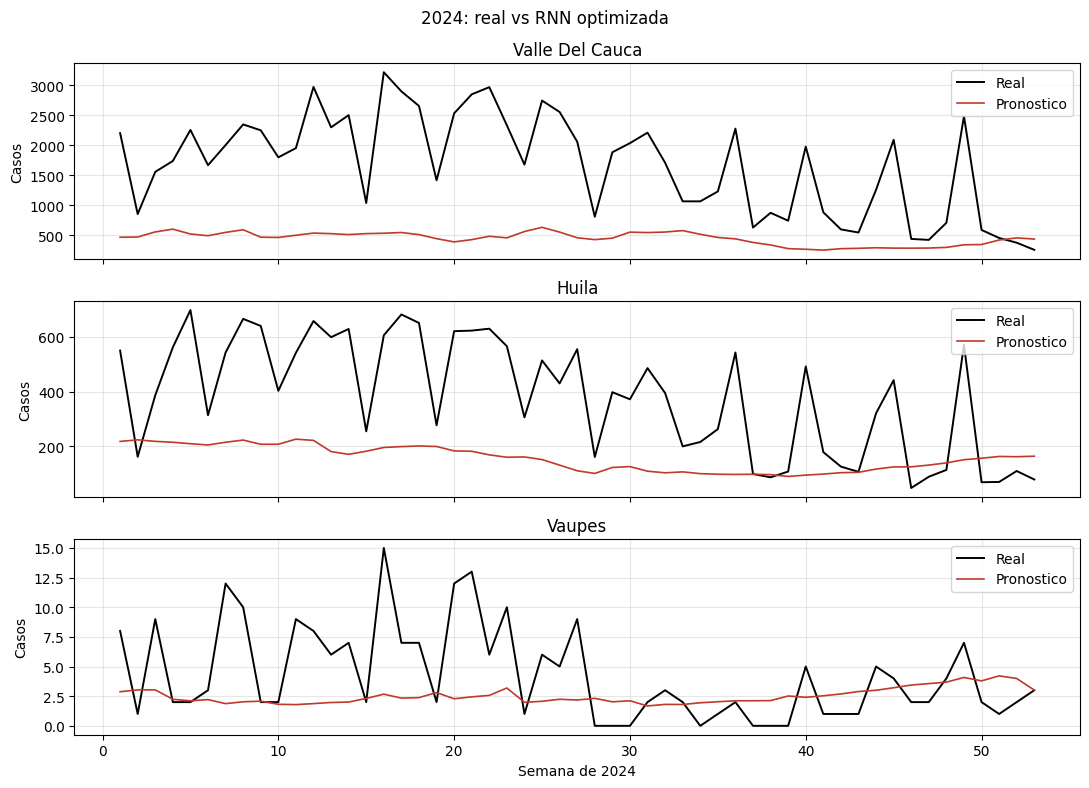

In [23]:
def add_reference(name, prediction):
    frame = pd.DataFrame({
        "y": features.loc[features.anio == VAL_YEAR, "casos_dengue"].to_numpy(),
        "pred": np.clip(prediction, 0, None),
        "semana": features.loc[features.anio == VAL_YEAR, "semana"].to_numpy(),
    })
    scores = regression_scores(frame)
    RESULTS.append({
        "modelo": name,
        "familia": "Referencia",
        "etapa": 0,
        "seq_len": 0,
        "residual": False,
        "n_features": 0,
        "n_params": 0,
        "epochs_ran": 0,
        **scores,
    })


val_2024 = features[features.anio == VAL_YEAR]
add_reference("Forma estacional escalada", val_2024["shape"].to_numpy())
add_reference("Misma semana del año anterior", val_2024["yoy"].to_numpy())
add_reference("Perfil estacional historico", val_2024["seas"].to_numpy())

summary = pd.DataFrame(RESULTS).sort_values("val_mse")
display(summary[["modelo", "familia", "etapa", "val_mse", "val_mae", "val_r2", "mse_h1", "mse_h2", "n_params"]].rename(columns={"val_mse": "mse_validacion", "val_mae": "mae_validacion", "val_r2": "r2_validacion", "mse_h1": "mse_semestre_1", "mse_h2": "mse_semestre_2", "n_params": "parametros"}).round(3))

best_stage1_name = summary[summary.etapa == 1].sort_values("val_mse").iloc[0]["modelo"]
print("Mejor red de la etapa 1 en 2024:", best_stage1_name)

preview = PREDICTIONS[best_stage1_name]
plot_departments = ["Valle Del Cauca", "Huila", "Vaupes"]


def plot_forecast(pred_df, title):
    fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
    for ax, dept in zip(axes, plot_departments):
        part = pred_df[pred_df.departamento == dept].sort_values("semana")
        ax.plot(part.semana, part.y, color="black", lw=1.4, label="Real")
        ax.plot(part.semana, part.pred, color="#C0392B", lw=1.2, label="Pronostico")
        ax.set_ylabel("Casos")
        ax.set_title(dept)
        ax.grid(alpha=0.3)
        ax.legend(loc="upper right")
    axes[-1].set_xlabel("Semana de 2024")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


plot_forecast(preview, f"2024: real vs {best_stage1_name}")

## Etapa 2. Corregir un perfil, no reinventar el nivel

2024 no se parece a la media de la decada anterior. Una red que tiene que inventar desde cero el nivel de Valle del Cauca gasta capacidad en algo que ya dice la historia reciente del departamento. La etapa 2 cambia la pregunta: el objetivo de entrenamiento pasa a ser el residual `casos - forma_estacional_escalada`, y al predecir se suma de nuevo esa forma. El MSE que se reporta y la parada temprana siguen calculados sobre los casos, no sobre el residual, porque esa es la metrica de Kaggle.

Las variables adicionales salen del analisis exploratorio: anclas de 8 y 26 semanas, perfil y rezago anual, anomalias climaticas, medias moviles de 4 semanas y viento en seno/coseno. Las redes de esta etapa son las versiones optimizadas de GRU, LSTM y TCN, que son las que mejor retienen una ventana larga.

El peso del ensamble no se elige mirando solo 2024. 2024 aplasta cualquier promedio de MSE porque sus errores son enormes. Se maximiza el R2 medio de 2022, 2023 y 2024, para que un año epidemico y un año tranquilo voten parejo. Eso protege a la vez el semestre que vera el tablero publico y el que vera el privado, sin conocer 2025.

In [24]:
STAGE2_SPECS = {
    "GRU residual": {
        "factory": lambda: RecurrentForecaster("gru", len(COLS_STAGE2), 96, 2, 0.2, head_hidden=64),
        "seq_len": 12,
        "train_kwargs": dict(lr=5e-4, weight_decay=1e-4, use_scheduler=True, optimizer_name="adamw"),
    },
    "LSTM residual": {
        "factory": lambda: RecurrentForecaster("lstm", len(COLS_STAGE2), 128, 2, 0.3, head_hidden=64),
        "seq_len": 16,
        "train_kwargs": dict(lr=5e-4, weight_decay=1e-4, use_scheduler=True, optimizer_name="adamw"),
    },
    "TCN residual": {
        "factory": lambda: TCNForecaster(len(COLS_STAGE2), (32, 32, 64), 5, 0.25, 4, "gelu"),
        "seq_len": 20,
        "train_kwargs": dict(lr=5e-4, weight_decay=1e-4, use_scheduler=True, optimizer_name="adamw"),
    },
}

VALIDACION_HISTORICA = {}


def validar_anio(name, spec, year):
    print(f"\n=== validacion historica {name} -> {year} ===")
    reset_seed(42)
    fit_mask = features["anio"] < year
    scaled, _scaler = scale_features(features, COLS_STAGE2, fit_mask)
    train_years = {int(value) for value in features.loc[fit_mask, "anio"].unique()}
    train_ds = WindowDataset(scaled, COLS_STAGE2, spec["seq_len"], train_years, True)
    val_ds = WindowDataset(scaled, COLS_STAGE2, spec["seq_len"], {year}, True)
    model, _history, _scores = train_forecaster(
        spec["factory"](),
        make_loader(train_ds, BATCH_SIZE, True),
        make_loader(val_ds, BATCH_SIZE, False),
        DEVICE,
        True,
        epochs=EPOCAS_VALIDACION,
        patience=PACIENCIA_VALIDACION,
        **spec["train_kwargs"],
    )
    preds = collect_predictions(model, make_loader(val_ds, BATCH_SIZE, False), DEVICE, True)
    VALIDACION_HISTORICA[(name, year)] = preds
    nombres_metrica = {
        "val_mse": "mse_validacion",
        "val_rmse": "raiz_mse",
        "val_r2": "r2_validacion",
        "mse_h1": "mse_semestre_1",
        "mse_h2": "mse_semestre_2",
    }
    visibles = {
        nombres_metrica[clave]: round(valor, 1)
        for clave, valor in regression_scores(preds).items()
        if clave in nombres_metrica and ("mse" in clave or clave == "val_r2")
    }
    print(name, year, visibles)
    return preds


for model_name, model_spec in STAGE2_SPECS.items():
    for holdout_year in (2022, 2023, 2024):
        validar_anio(model_name, model_spec, holdout_year)


=== validacion historica GRU residual -> 2022 ===


  epoca 01 | entrenamiento 6721.7 | validacion 1284.4 | semestre 1 1206.1 | semestre 2 1362.7


  epoca 02 | entrenamiento 6168.7 | validacion 1152.7 | semestre 1 1087.2 | semestre 2 1218.2


  epoca 03 | entrenamiento 5608.0 | validacion 1067.5 | semestre 1 971.6 | semestre 2 1163.4


  epoca 04 | entrenamiento 5064.2 | validacion 918.5 | semestre 1 810.8 | semestre 2 1026.1


  epoca 05 | entrenamiento 4613.9 | validacion 1006.3 | semestre 1 962.6 | semestre 2 1050.0


... (74 outputs left out)

  epoca 09 | entrenamiento 2826.6 | validacion 53090.6 | semestre 1 73828.0 | semestre 2 33121.2


  epoca 10 | entrenamiento 2621.7 | validacion 61335.8 | semestre 1 82319.8 | semestre 2 41128.9


  epoca 11 | entrenamiento 2495.7 | validacion 54419.1 | semestre 1 74266.2 | semestre 2 35307.0


  epoca 12 | entrenamiento 2358.3 | validacion 56666.7 | semestre 1 78445.2 | semestre 2 35694.8
TCN residual 2024 {'mse_validacion': 53090.6, 'raiz_mse': 230.4, 'r2_validacion': 0.6, 'mse_semestre_1': 73828.0, 'mse_semestre_2': 33121.2}


In [25]:
def year_bundle(year):
    base = features.loc[features.anio == year, ["ID", "casos_dengue", "semana", "departamento", "shape", "seas", "yoy"]].rename(
        columns={"casos_dengue": "y"}
    )
    merged = base.copy()
    for model_name in STAGE2_SPECS:
        part = VALIDACION_HISTORICA[(model_name, year)][["ID", "pred"]].rename(columns={"pred": model_name})
        merged = merged.merge(part, on="ID", how="inner")
    for column in ["shape", "seas", "yoy"]:
        merged[column] = merged[column].clip(lower=0)
    return merged


def compositions(n_parts, total):
    if n_parts == 1:
        yield (total,)
        return
    for count in range(total + 1):
        for rest in compositions(n_parts - 1, total - count):
            yield (count,) + rest


BLEND_NAMES = ["GRU residual", "LSTM residual", "TCN residual", "shape"]
bundles = {year: year_bundle(year) for year in (2022, 2023, 2024)}
for year, bundle in bundles.items():
    print(year, "filas alineadas", len(bundle), "de", int((features.anio == year).sum()))

best_weights = None
best_r2 = -1e9
weight_rows = []
for counts in compositions(len(BLEND_NAMES), 10):
    weights = np.array(counts, dtype=float) / 10.0
    r2_values = []
    mse_values = []
    for bundle in bundles.values():
        prediction = np.clip(sum(weights[i] * bundle[name].to_numpy() for i, name in enumerate(BLEND_NAMES)), 0, None)
        r2_values.append(r2_score(bundle.y, prediction))
        mse_values.append(mean_squared_error(bundle.y, prediction))
    mean_r2 = float(np.mean(r2_values))
    weight_rows.append({"peso_" + ("forma" if name == "shape" else name): weights[i] for i, name in enumerate(BLEND_NAMES)} | {
        "r2_medio": mean_r2,
        "mse_2022": mse_values[0],
        "mse_2023": mse_values[1],
        "mse_2024": mse_values[2],
    })
    if mean_r2 > best_r2:
        best_r2 = mean_r2
        best_weights = weights

weight_table = pd.DataFrame(weight_rows).sort_values("r2_medio", ascending=False)
print("Mejor peso por R2 medio de 2022-2024:", dict(zip(["GRU residual", "LSTM residual", "TCN residual", "forma"], best_weights.round(2))), "R2 medio", round(best_r2, 3))
display(weight_table.head(8).round(3))

single_rows = []
for model_name in list(STAGE2_SPECS) + ["shape", "yoy", "seas"]:
    record = {"modelo": model_name}
    for year, bundle in bundles.items():
        column = model_name if model_name in bundle.columns else None
        prediction = bundle[model_name].to_numpy() if column else None
        if prediction is None:
            continue
        record[f"mse_{year}"] = mean_squared_error(bundle.y, np.clip(prediction, 0, None))
        record[f"r2_{year}"] = r2_score(bundle.y, np.clip(prediction, 0, None))
    single_rows.append(record)
blend_record = {"modelo": "Ensamble"}
for year, bundle in bundles.items():
    prediction = np.clip(sum(best_weights[i] * bundle[name].to_numpy() for i, name in enumerate(BLEND_NAMES)), 0, None)
    blend_record[f"mse_{year}"] = mean_squared_error(bundle.y, prediction)
    blend_record[f"r2_{year}"] = r2_score(bundle.y, prediction)
    bundle["ensamble"] = prediction
single_rows.append(blend_record)
comparison = pd.DataFrame(single_rows).set_index("modelo")
display(comparison.rename(index={"shape": "forma", "yoy": "año anterior", "seas": "perfil"}).round(3))

2022 filas alineadas 1612 de 1612
2023 filas alineadas 1612 de 1612
2024 filas alineadas 1643 de 1643


Mejor peso por R2 medio de 2022-2024: {'GRU residual': np.float64(0.7), 'LSTM residual': np.float64(0.0), 'TCN residual': np.float64(0.3), 'forma': np.float64(0.0)} R2 medio 0.509


,peso_GRU residual,peso_LSTM residual,peso_TCN residual,peso_forma,r2_medio,mse_2022,mse_2023,mse_2024
269,0.7,0.0,0.3,0.0,0.509,895.393,9881.882,56119.230
278,0.8,0.0,0.2,0.0,0.508,897.000,9810.792,56792.781
255,0.6,0.0,0.4,0.0,0.508,899.864,9968.023,55505.901
283,0.9,0.0,0.1,0.0,0.507,904.687,9754.753,57526.554
235,0.5,0.0,0.5,0.0,0.505,910.413,10069.217,54952.794
272,0.7,0.1,0.2,0.0,0.505,894.910,9991.719,56650.243
259,0.6,0.1,0.3,0.0,0.504,894.898,10069.660,55998.767
285,1.0,0.0,0.0,0.0,0.504,918.452,9713.766,58320.549


,mse_2022,r2_2022,mse_2023,r2_2023,mse_2024,r2_2024
modelo,,,,,,
GRU residual,918.452,0.667,9713.767,0.306,58320.551,0.539
LSTM residual,959.893,0.652,11839.256,0.154,57860.043,0.543
TCN residual,1054.338,0.618,10800.955,0.228,53090.590,0.580
forma,1444.730,0.477,13638.918,0.025,76519.082,0.395
año anterior,1803.411,0.347,13204.339,0.056,117021.758,0.075
perfil,3143.054,-0.138,9946.629,0.289,122123.779,0.034
Ensamble,895.393,0.676,9881.882,0.294,56119.230,0.556


### Validación de la etapa 2 en 2023 y 2024

El ensamble de la etapa 2 mejora la forma estacional en los tres cortes, pero copia el nivel del año anterior. Su archivo de 2025 tenía media de 105 casos por departamento y semana, y Valle del Cauca cerca de 700 en el segundo semestre. Contra un segundo semestre como el de 2018 o el de 2022 ese nivel da errores de 14.000 a 22.000. Por eso no se sube, y las etapas 3 y 4 cambian la forma de validar: un año a la vez, partido en semestres.

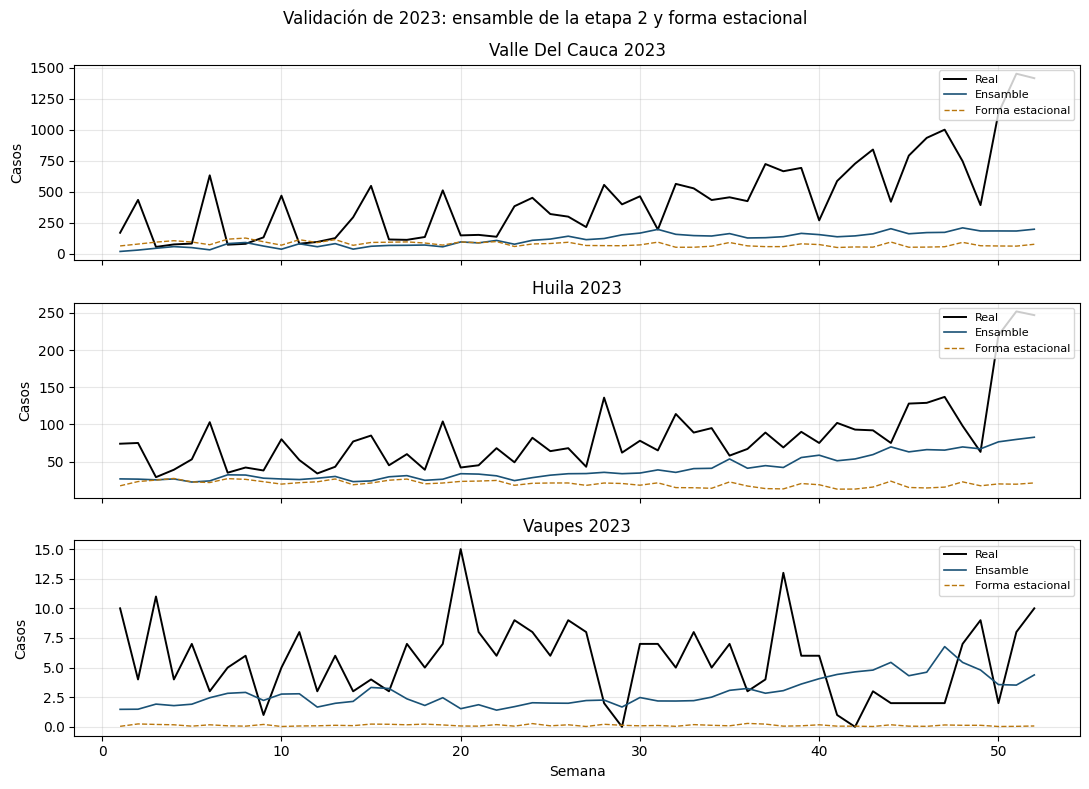

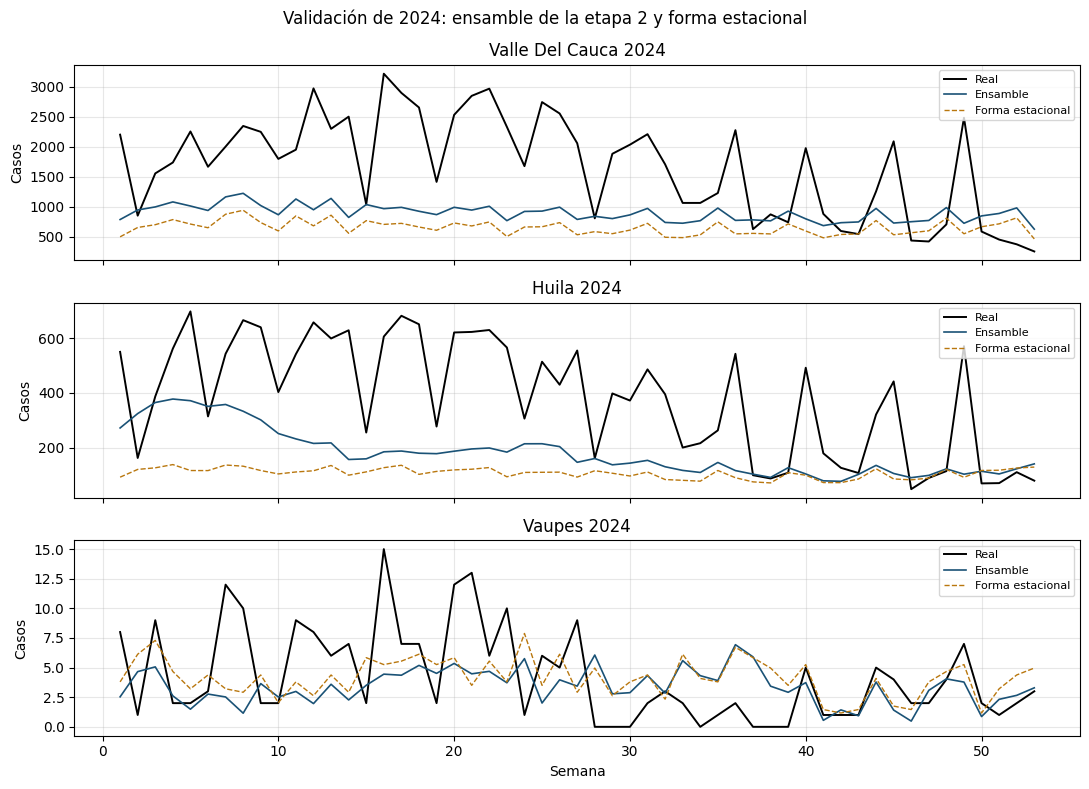

Pesos de la etapa 2: {'GRU residual': 0.7, 'LSTM residual': 0.0, 'TCN residual': 0.3, 'forma': 0.0}


In [26]:
for holdout_year in (2023, 2024):
    bundle = bundles[holdout_year]
    fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
    for ax, dept in zip(axes, plot_departments):
        part = bundle[bundle.departamento == dept].sort_values("semana")
        ax.plot(part.semana, part.y, color="black", lw=1.4, label="Real")
        ax.plot(part.semana, part.ensamble, color="#1A5276", lw=1.2, label="Ensamble")
        ax.plot(part.semana, part["shape"], color="#B9770E", lw=1, ls="--", label="Forma estacional")
        ax.set_title(f"{dept} {holdout_year}")
        ax.set_ylabel("Casos")
        ax.grid(alpha=0.3)
        ax.legend(loc="upper right", fontsize=8)
    axes[-1].set_xlabel("Semana")
    fig.suptitle(f"Validación de {holdout_year}: ensamble de la etapa 2 y forma estacional")
    plt.tight_layout()
    plt.show()

print("Pesos de la etapa 2:", dict(zip(["GRU residual", "LSTM residual", "TCN residual", "forma"], [round(float(w), 2) for w in best_weights])))

## Etapa 3. Bases epidemiológicas por horizonte

Las etapas 1 y 2 se validaron con un solo corte, 2024, y con los dos semestres juntos. El tablero no funciona así: el público mide julio a diciembre de 2025 y el privado, que define el puesto, enero a junio. Además 2024 fue un brote sin precedentes.

Esta etapa no usa redes. Es la referencia estadística que usaron los envíos públicos y el segundo semestre del archivo final. Para cada año Y se arman siete bases, todas con años anteriores a Y:

- mediana y media histórica por semana, la media con tope en 2 veces el nivel de referencia para que un brote no la arrastre;
- media de los últimos 6 años, mediana de los últimos 5 y media de los últimos 3, con tope;
- el cierre de diciembre de Y-1, directo y escalado al perfil reciente, para las primeras semanas.

Los pesos de esas bases se ajustan por mínimos cuadrados, restringidos a [0, 1] y encogidos hacia el promedio, con los años anteriores a Y que no fueron brote, por separado para las semanas 1-13, 14-26 y 27-52. Es el envío de horizontes: 2048,50 en el tablero público. Todo se evalúa en walk-forward: para Y solo se usa lo anterior a Y.

In [27]:
from scipy.optimize import minimize

BASES_B = ["b_med_all", "b_mean_all", "b_rec6", "b_med5", "b_rec3", "b_end_direct", "b_end_scaled"]
ANIOS_B = list(range(2011, 2026))


def suavizar(serie):
    """Media movil centrada de 5 semanas sobre el perfil semanal, circular entre diciembre y enero."""
    tabla = serie.unstack("semana")
    columnas = [semana for semana in range(1, 53) if semana in tabla.columns]
    tabla = tabla[columnas]
    extendida = pd.concat([tabla[columnas[-2:]], tabla, tabla[columnas[:2]]], axis=1)
    suave = extendida.T.rolling(5, center=True, min_periods=1).mean().T.iloc[:, 2:-2]
    suave.columns = pd.Index(columnas, name="semana")
    return suave.stack()


def marco_bases(hist, cur):
    """Las siete bases del ano de `cur`, calculadas solo con `hist` (anos anteriores)."""
    anio = int(cur.anio.iloc[0])
    mediana_6 = hist[hist.anio >= anio - 6].groupby("id_departamento").casos_dengue.median()
    mediana_hist = hist.groupby("id_departamento").casos_dengue.median()
    referencia = np.maximum(mediana_6, mediana_hist).replace(0, 1.0)
    historia_baja = hist.copy()
    historia_alta = hist.copy()
    historia_baja["casos_dengue"] = np.minimum(hist.casos_dengue, hist.id_departamento.map(referencia * 2.0))
    historia_alta["casos_dengue"] = np.minimum(hist.casos_dengue, hist.id_departamento.map(referencia * 2.8))
    perfiles = {
        "b_med_all": suavizar(hist.groupby(["id_departamento", "semana"]).casos_dengue.median()),
        "b_mean_all": suavizar(historia_baja.groupby(["id_departamento", "semana"]).casos_dengue.mean()),
        "b_rec6": suavizar(historia_baja[historia_baja.anio >= anio - 6].groupby(["id_departamento", "semana"]).casos_dengue.mean()),
        "b_med5": suavizar(hist[hist.anio >= anio - 5].groupby(["id_departamento", "semana"]).casos_dengue.median()),
        "b_rec3": suavizar(historia_alta[historia_alta.anio >= anio - 3].groupby(["id_departamento", "semana"]).casos_dengue.mean()),
    }
    previo = hist[hist.anio == anio - 1]
    cierre_2 = previo[previo.semana >= 51].groupby("id_departamento").casos_dengue.mean()
    cierre_6 = previo[previo.semana >= 47].groupby("id_departamento").casos_dengue.mean()
    cierre_12 = previo[previo.semana >= 41].groupby("id_departamento").casos_dengue.mean()
    cierre = 0.50 * cierre_2 + 0.35 * cierre_6 + 0.15 * cierre_12
    mitad_1 = previo[previo.semana <= 26].groupby("id_departamento").casos_dengue.mean()
    trimestre_2 = previo[previo.semana.between(14, 26)].groupby("id_departamento").casos_dengue.mean()
    media_previa = previo.groupby("id_departamento").casos_dengue.mean()
    nivel = perfiles["b_rec6"].unstack("semana").mean(axis=1).replace(0, 1.0)
    nivel_cierre = perfiles["b_rec6"].unstack("semana")[[47, 48, 49, 50, 51, 52]].mean(axis=1).replace(0, 1.0)
    pico = np.maximum(mitad_1, trimestre_2).replace(0, 1.0)
    es_caida = (media_previa > 2.2 * nivel) & (cierre < 0.65 * pico)
    razon = (cierre / nivel_cierre).fillna(1.0)
    razon_suave = pd.Series(
        np.where(razon > 1.15, 1.15 + np.log1p(np.maximum(razon - 1.15, 0.0)), np.clip(razon, 0.25, 1.15)),
        index=razon.index,
    )
    indice = pd.MultiIndex.from_arrays([cur.id_departamento, cur.semana])
    salida = cur[["id_departamento", "anio", "semana"]].copy()
    for nombre, serie in perfiles.items():
        salida[nombre] = serie.reindex(indice).fillna(0.0).to_numpy()
    caida = cur.id_departamento.map(es_caida).fillna(False).astype(float).to_numpy()
    razon_fila = np.where(caida > 0.5, 0.85, cur.id_departamento.map(razon_suave).fillna(1.0).to_numpy())
    cierre_fila = cur.id_departamento.map(cierre).fillna(0.0).to_numpy()
    salida["b_end_direct"] = np.where(caida > 0.5, salida["b_med_all"], np.minimum(cierre_fila, 2.2 * salida["b_rec6"]))
    salida["b_end_scaled"] = salida["b_rec6"].to_numpy() * razon_fila
    if "casos_dengue" in cur.columns and cur.casos_dengue.notna().all():
        salida["y"] = cur.casos_dengue.to_numpy(float)
        media_actual = cur.groupby("id_departamento").casos_dengue.mean()
        salida["brote"] = cur.id_departamento.map(media_actual > 2.3 * nivel).fillna(False).to_numpy()
    else:
        salida["y"] = np.nan
        salida["brote"] = False
    return salida.reset_index(drop=True)


def pesos_horizonte(marcos, semana_min, semana_max):
    """Minimos cuadrados con pesos en [0, 1] y una penalizacion que los acerca al promedio simple."""
    entrenamiento = pd.concat([t.loc[t.semana.between(semana_min, semana_max) & ~t.brote] for t in marcos], ignore_index=True)
    matriz = entrenamiento[BASES_B].to_numpy(float)
    objetivo = entrenamiento.y.to_numpy(float)
    escala = float(np.mean(matriz**2))
    centro = np.full(len(BASES_B), 1.0 / len(BASES_B))

    def costo(pesos):
        return float(np.mean((matriz @ pesos - objetivo) ** 2) + 0.05 * escala * np.sum((pesos - centro) ** 2))

    return minimize(costo, centro, bounds=[(0.0, 1.0)] * len(BASES_B)).x


def aplicar_pesos(tabla, peso_q1, peso_q2, peso_h2):
    matriz = tabla[BASES_B].to_numpy(float)
    semana = tabla.semana.to_numpy()
    return np.where(semana <= 13, matriz @ peso_q1, np.where(semana <= 26, matriz @ peso_q2, matriz @ peso_h2))


train_b = train.sort_values(["id_departamento", "anio", "semana"]).reset_index(drop=True)
test_b = test.sort_values(["id_departamento", "anio", "semana"]).reset_index(drop=True)
marcos_b = {}
for anio in range(2010, 2025):
    actual = train_b[(train_b.anio == anio) & (train_b.semana <= 52)].reset_index(drop=True)
    marcos_b[anio] = marco_bases(train_b[train_b.anio < anio], actual)
marcos_b[2025] = marco_bases(train_b, test_b)

piezas, pesos_b = [], {}
for anio in ANIOS_B:
    previos = [marcos_b[a] for a in range(2010, anio)]
    pesos_b[anio] = [pesos_horizonte(previos, a, b) for a, b in ((1, 13), (14, 26), (27, 52))]
    tabla = marcos_b[anio][["id_departamento", "anio", "semana", "y"]].copy()
    tabla["b"] = np.clip(aplicar_pesos(marcos_b[anio], *pesos_b[anio]), 0, None)
    piezas.append(tabla)
B_WF = pd.concat(piezas, ignore_index=True)

errores_b = []
for anio in range(2014, 2025):
    t = B_WF[B_WF.anio == anio]
    h1 = t.semana <= 26
    errores_b.append({
        "anio": anio,
        "mse_semestre_1": mean_squared_error(t.y[h1], t.b[h1]),
        "mse_semestre_2": mean_squared_error(t.y[~h1], t.b[~h1]),
    })
errores_b = pd.DataFrame(errores_b).set_index("anio")
MSE_B_H1 = errores_b.mse_semestre_1
display(errores_b.round(0).T)
print(
    "Media 2014-2023 | semestre 1:", round(errores_b.loc[2014:2023, "mse_semestre_1"].mean()),
    "| semestre 2:", round(errores_b.loc[2014:2023, "mse_semestre_2"].mean()),
)
print("Pesos de 2025 por tramo:")
for nombre, pesos in zip(["semanas 1-13", "semanas 14-26", "semanas 27-52"], pesos_b[2025]):
    print(" ", nombre, dict(zip(BASES_B, np.round(pesos, 2))))

B_2025 = B_WF[B_WF.anio == 2025].copy()
B_2025["id"] = B_2025.id_departamento.astype(str) + "_2025_" + B_2025.semana.astype(str)
B_2025 = B_2025.set_index("id").b.loc[sample.id]
envio_horizontes = repo_root() / "ensayos/juan/2026-10-31-horizonte-bases/submission.csv"
if envio_horizontes.exists():
    subido = pd.read_csv(envio_horizontes).set_index("id").dengue.loc[sample.id]
    print("Diferencia máxima con el envío público de horizontes (2048,50):", float(np.abs(subido - B_2025).max()))

anio,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
mse_semestre_1,1419.0,2647.0,9743.0,1120.0,416.0,4886.0,8399.0,581.0,1021.0,5109.0,152278.0
mse_semestre_2,2068.0,2100.0,8117.0,968.0,1505.0,7714.0,3326.0,3943.0,2433.0,19464.0,65749.0


Media 2014-2023 | semestre 1: 3534 | semestre 2: 5164
Pesos de 2025 por tramo:
  semanas 1-13 {'b_med_all': np.float64(0.0), 'b_mean_all': np.float64(0.0), 'b_rec6': np.float64(0.03), 'b_med5': np.float64(0.0), 'b_rec3': np.float64(0.0), 'b_end_direct': np.float64(0.42), 'b_end_scaled': np.float64(0.63)}
  semanas 14-26 {'b_med_all': np.float64(0.0), 'b_mean_all': np.float64(0.02), 'b_rec6': np.float64(0.13), 'b_med5': np.float64(0.0), 'b_rec3': np.float64(0.0), 'b_end_direct': np.float64(0.31), 'b_end_scaled': np.float64(0.53)}
  semanas 27-52 {'b_med_all': np.float64(0.0), 'b_mean_all': np.float64(0.15), 'b_rec6': np.float64(0.2), 'b_med5': np.float64(0.08), 'b_rec3': np.float64(0.0), 'b_end_direct': np.float64(0.21), 'b_end_scaled': np.float64(0.29)}
Diferencia máxima con el envío público de horizontes (2048,50): 5.684341886080802e-14


Las bases fallan en los años de brote (2016, 2019, 2023 y sobre todo 2024): ningún promedio de años anteriores anticipa un brote. En los años normales quedan en la escala del tablero.

En 2025 los pesos de las semanas 1-13 van casi enteros a las dos bases del cierre de diciembre. Esas bases tienen una regla de caída: si el año anterior superó 2,2 veces lo normal y el cierre quedó por debajo del 65 % del pico, se asume un colapso y la base pasa a la mediana histórica, o a 0,85 veces el perfil reciente. Con 2024 la regla se activa en 15 departamentos del interior, entre ellos Valle del Cauca, Santander, Tolima, Huila y Cundinamarca. Por eso B abre enero de 2025 muy por debajo de diciembre en el interior y no en la Costa, que al cierre de 2024 todavía venía subiendo.

## Etapa 4. Redes para el primer semestre

El tablero privado es el primer semestre de 2025, pronosticado desde la última semana de 2024. Esta etapa entrena las cinco familias de redes para esa tarea exacta y las mide igual: para cada año Y de 2011 a 2024, la red solo ve ventanas cuyo objetivo termina antes del 1 de enero de Y, y pronostica las semanas 1 a 26 de Y desde la última semana de Y-1.

**Organización de los datos.** Cada ejemplo es una ventana rodante con origen en cualquier semana: 52 semanas de entrada y las 26 siguientes como objetivo. Son unas 26.700 ventanas para 2025, frente a las 31 transiciones de diciembre a enero que hay por año. La red recibe tres bloques:

- **Pasado (52 x 10).** Casos en log relativos al nivel reciente (mediana de las últimas 8 semanas, que ignora los lotes de reporte), seno y coseno de la semana, la marca de semana de lote, la marca de fin de año y cinco anomalías de clima (lluvia, temperatura media y mínima, punto de rocío y humedad del suelo) contra la climatología 2007-2013, que no incluye ningún año validado.
- **Futuro (26 x 11).** El mismo calendario, el clima de esas semanas (en 2025 viene en `test.parquet`), el perfil estacional del departamento relativo al nivel actual y el horizonte.
- **Estáticas (4).** Nivel actual, nivel frente a lo normal de los 8 años previos, distancia al pico de las últimas 52 semanas y casos acumulados frente a lo normal.

Cada familia lee el pasado a su manera. El MLP aplana la ventana a un vector de 520 valores. RNN, LSTM y GRU la recorren paso a paso y entregan el último estado oculto. La TCN la transpone a (variables, tiempo), aplica convoluciones causales con dilatación 1, 2, 4 y 8, y toma el último paso. En los cinco casos, el resumen del pasado se repite en las 26 semanas futuras, se une con el futuro y las estáticas, y una cabeza común produce cada semana.

**Salida y pérdida.** La cabeza no predice casos sueltos. Para cada semana futura elige un punto entre la persistencia del nivel actual y el perfil estacional, más un residuo acotado de ±0,5 en logaritmo. La pérdida es Poisson: su mínimo es la media condicional, la misma que premia el MSE.

**Cambios frente al código base del curso**

| Hiperparámetro | Código base | Etapa 4 |
| --- | --- | --- |
| Ventana de entrada | 5 semanas | 52 semanas |
| Salida | 1 semana, ReLU o lineal | 26 semanas, compuerta entre persistencia y perfil |
| Pérdida | MSE | Poisson |
| Optimizador | Adam 1e-3 | AdamW con weight decay 1e-4 (1e-3 en MLP y TCN, 2e-3 en las recurrentes) |
| Lote y épocas | 32 o 64, 20 o 30 épocas | 512, 12 épocas fijas |
| MLP | 1 capa de 64 | 2 capas de 64, dropout 0,2 |
| RNN, LSTM, GRU | (no hay en el código base; en la etapa 1, 1 capa de 32) | 1 capa de 32, dropout 0,1 en la cabeza |
| TCN | canales [32, 32, 64, 64], GroupNorm | 4 niveles de 32 canales, sin normalización, campo receptivo de 61 semanas para una ventana de 52 |

In [28]:
from dataclasses import asdict, dataclass, replace

HORIZONTE = 26
VENTANA = 52
CLIMA_RED = ["precip_chirps_mm", "temp_media_C", "temp_min_C", "punto_rocio_C", "humedad_suelo_capa1"]
ANIOS_CLIMATOLOGIA = range(2007, 2014)
ANIOS_PERFIL = 8
LOTE_RED = 512
DISPOSITIVO = DEVICE
ANIOS_WF = list(range(2011, 2026))
ANIOS_EVAL = list(range(2014, 2024))
SEMILLAS_WF = [0, 1]
SEMILLAS_REPLICA = [2, 3, 4]
SEMILLAS_2025 = [0, 1, 2, 3, 4]
EPOCAS_RED = 12


@dataclass(frozen=True)
class ConfigRed:
    familia: str
    oculto: int = 32
    capas: int = 1
    dropout: float = 0.1
    lr: float = 2e-3
    wd: float = 1e-4
    kernel: int = 3
    cabeza: int = 32
    salida: str = "compuerta"
    residuo: float = 0.5
    peso_fin: float = 1.0


CONFIGS_RED = {
    "mlp": ConfigRed("mlp", oculto=64, dropout=0.2, lr=1e-3),
    "rnn": ConfigRed("rnn"),
    "lstm": ConfigRed("lstm"),
    "gru": ConfigRed("gru"),
    "tcn": ConfigRed("tcn", capas=4, lr=1e-3),
}


class Panel:
    """Series semanales de los 31 departamentos en una grilla [departamento, tiempo], 2007 a 2025."""

    def __init__(self, full, calmo=False):
        self.calmo = calmo
        self.deptos = np.sort(full.id_departamento.unique())
        self.D = len(self.deptos)
        self.T = len(full) // self.D
        primera = full[full.id_departamento == self.deptos[0]]
        for d in self.deptos[1:]:
            if not np.array_equal(full.loc[full.id_departamento == d, "semana_inicio"].to_numpy(), primera.semana_inicio.to_numpy()):
                raise RuntimeError("Los departamentos no comparten el calendario.")
        self.anio = primera.anio.to_numpy()
        self.semana = primera.semana.to_numpy()
        self.inicio = pd.to_datetime(primera.semana_inicio.to_numpy())
        self.Y = full.casos_dengue.to_numpy(float).reshape(self.D, self.T)
        clima = full[CLIMA_RED].to_numpy(float).reshape(self.D, self.T, len(CLIMA_RED))
        self.calendario = self._calendario()
        self.clima_z = self._anomalias(clima)
        self.perfiles, self.normal = self._perfiles()

    def _calendario(self):
        angulo = 2 * np.pi * (self.semana - 1) / 52.18
        miercoles = self.inicio + pd.Timedelta(days=2)
        lote = (miercoles.day <= 7).astype(float)
        fin_anio = (((self.inicio.month == 12) & (self.inicio.day >= 26)) | ((self.inicio.month == 1) & (self.inicio.day == 1))).astype(float)
        return np.stack([np.sin(angulo), np.cos(angulo), lote, fin_anio], axis=1)

    def _anomalias(self, clima):
        semana = np.minimum(self.semana, 52)
        base = np.isin(self.anio, list(ANIOS_CLIMATOLOGIA))
        z = np.zeros_like(clima)
        for d in range(self.D):
            escala = clima[d, base].std(axis=0)
            escala = np.where(escala < 1e-6, 1.0, escala)
            for s in range(1, 53):
                filas = semana == s
                z[d, filas] = (clima[d, filas] - clima[d, base & filas].mean(axis=0)) / escala
        return np.clip(z, -4, 4)

    def _perfiles(self):
        """Perfil estacional y nivel normal por ano de inicio P, solo con anos completos anteriores a P."""
        perfiles, normal = {}, {}
        semana = np.minimum(self.semana, 52)
        for P in range(2008, int(self.anio.max()) + 1):
            anios = [a for a in range(P - ANIOS_PERFIL, P) if a >= 2007]
            tabla = np.full((self.D, 53), np.nan)
            normal[P] = np.zeros(self.D)
            for d in range(self.D):
                usar = anios
                if self.calmo and len(anios) >= 3:
                    medias = np.array([np.nanmean(self.Y[d, self.anio == a]) for a in anios])
                    usar = [a for a, m in zip(anios, medias) if m <= 2.0 * np.median(medias)] or anios
                mascara = np.isin(self.anio, usar)
                for s in range(1, 53):
                    tabla[d, s] = np.nanmedian(self.Y[d, mascara & (semana == s)])
                normal[P][d] = np.nanmedian(self.Y[d, mascara])
            circular = np.concatenate([tabla[:, 51:53], tabla[:, 1:53], tabla[:, 1:3]], axis=1)
            suave = np.stack([circular[:, i : i + 5].mean(axis=1) for i in range(52)], axis=1)
            perfil = np.zeros((self.D, 54))
            perfil[:, 1:53] = suave
            perfil[:, 53] = suave[:, 51]
            perfiles[P] = perfil
        return perfiles, normal

    def ultimo_indice(self, anio):
        return int(np.where(self.anio == anio)[0].max())


def ventanas(panel):
    """Todas las ventanas. Las de objetivo desconocido (2025) solo sirven para pronosticar."""
    origenes = np.arange(VENTANA - 1, panel.T - HORIZONTE)
    origenes = origenes[panel.anio[origenes + 1] >= 2008]
    D, n = panel.D, len(origenes)
    enc = np.zeros((D, n, VENTANA, 1 + panel.calendario.shape[1] + len(CLIMA_RED)), np.float32)
    dec = np.zeros((D, n, HORIZONTE, panel.calendario.shape[1] + len(CLIMA_RED) + 2), np.float32)
    est = np.zeros((D, n, 4), np.float32)
    obj = np.zeros((D, n, HORIZONTE), np.float32)
    nivel = np.zeros((D, n), np.float32)
    logY = np.log1p(panel.Y)
    for j, t in enumerate(origenes):
        pasado = slice(t - VENTANA + 1, t + 1)
        futuro = slice(t + 1, t + 1 + HORIZONTE)
        logL = np.log1p(np.median(panel.Y[:, t - 7 : t + 1], axis=1))
        P = int(panel.anio[t + 1])
        enc[:, j, :, 0] = logY[:, pasado] - logL[:, None]
        enc[:, j, :, 1:5] = panel.calendario[pasado][None]
        enc[:, j, :, 5:] = panel.clima_z[:, pasado]
        dec[:, j, :, 0:4] = panel.calendario[futuro][None]
        dec[:, j, :, 4:9] = panel.clima_z[:, futuro]
        dec[:, j, :, 9] = np.log1p(panel.perfiles[P][:, panel.semana[futuro]]) - logL[:, None]
        dec[:, j, :, 10] = np.arange(1, HORIZONTE + 1)[None] / HORIZONTE
        normal = panel.normal[P]
        media4 = pd.DataFrame(panel.Y[:, pasado].T).rolling(4).mean().max().to_numpy()
        est[:, j, 0] = logL / 7.0
        est[:, j, 1] = logL - np.log1p(normal)
        est[:, j, 2] = np.log1p(media4) - logL
        est[:, j, 3] = np.log1p(panel.Y[:, pasado].sum(axis=1)) - np.log1p(VENTANA * normal)
        obj[:, j] = panel.Y[:, futuro]
        nivel[:, j] = logL
    semana_origen = np.broadcast_to(panel.semana[origenes][None], (D, n)).astype(np.float32)
    return {"origenes": origenes, "enc": enc, "dec": dec, "est": est, "obj": obj, "nivel": nivel, "semana_origen": semana_origen}


class Tensores:
    def __init__(self, V):
        D, n = V["nivel"].shape
        aplanar = lambda a: torch.tensor(np.ascontiguousarray(a).reshape(D * n, *a.shape[2:]), device=DISPOSITIVO)
        self.enc, self.dec, self.est = aplanar(V["enc"]), aplanar(V["dec"]), aplanar(V["est"])
        self.obj = aplanar(np.nan_to_num(V["obj"], nan=0.0))
        self.nivel = aplanar(V["nivel"])
        self.semana_origen = aplanar(V["semana_origen"])
        self.n = n

    def indice(self, d, j):
        return torch.tensor(np.asarray(d) * self.n + np.asarray(j), device=DISPOSITIVO, dtype=torch.long)


full_red = pd.concat([train, test.assign(casos_dengue=np.nan)], ignore_index=True)
full_red = full_red.sort_values(["id_departamento", "semana_inicio"]).reset_index(drop=True)
panel = Panel(full_red)
V = ventanas(panel)
X = Tensores(V)
print("Departamentos", panel.D, "| semanas por departamento", panel.T, "| ventanas", V["enc"].shape[0] * V["enc"].shape[1])
print("Pasado:", tuple(V["enc"].shape[2:]), "| futuro:", tuple(V["dec"].shape[2:]), "| estáticas:", V["est"].shape[-1])

Departamentos 31 | semanas por departamento 992 | ventanas 28334
Pasado: (52, 10) | futuro: (26, 11) | estáticas: 4


In [29]:
class BloqueTCN(nn.Module):
    def __init__(self, entrada, salida, kernel, dilatacion, dropout):
        super().__init__()
        self.recorte = (kernel - 1) * dilatacion
        self.c1 = nn.Conv1d(entrada, salida, kernel, dilation=dilatacion, padding=self.recorte)
        self.c2 = nn.Conv1d(salida, salida, kernel, dilation=dilatacion, padding=self.recorte)
        self.residuo = nn.Conv1d(entrada, salida, 1) if entrada != salida else nn.Identity()
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        o = self.dropout(torch.relu(self.c1(x)[..., : -self.recorte]))
        o = self.dropout(torch.relu(self.c2(o)[..., : -self.recorte]))
        return torch.relu(o + self.residuo(x))


class Pronosticador(nn.Module):
    """Codificador del pasado segun la familia y una cabeza comun para las 26 semanas futuras."""

    def __init__(self, cfg, n_enc, n_est, n_dec):
        super().__init__()
        self.familia, self.salida, self.residuo = cfg.familia, cfg.salida, cfg.residuo
        if cfg.familia == "mlp":
            self.codificador = nn.Sequential(
                nn.Flatten(), nn.Linear(VENTANA * n_enc, cfg.oculto), nn.ReLU(), nn.Dropout(cfg.dropout),
                nn.Linear(cfg.oculto, cfg.oculto), nn.ReLU(),
            )
        elif cfg.familia in ("rnn", "lstm", "gru"):
            celda = {"rnn": nn.RNN, "lstm": nn.LSTM, "gru": nn.GRU}[cfg.familia]
            self.codificador = celda(n_enc, cfg.oculto, num_layers=cfg.capas, batch_first=True, dropout=cfg.dropout if cfg.capas > 1 else 0.0)
        else:
            bloques, entrada = [], n_enc
            for nivel in range(cfg.capas):
                bloques.append(BloqueTCN(entrada, cfg.oculto, cfg.kernel, 2**nivel, cfg.dropout))
                entrada = cfg.oculto
            self.codificador = nn.Sequential(*bloques)
        self.cabeza = nn.Sequential(
            nn.Linear(cfg.oculto + n_est + n_dec, cfg.cabeza), nn.ReLU(), nn.Dropout(cfg.dropout), nn.Linear(cfg.cabeza, 2)
        )

    def codificar(self, x):
        if self.familia == "mlp":
            return self.codificador(x)
        if self.familia == "tcn":
            return self.codificador(x.transpose(1, 2))[:, :, -1]
        salida, _ = self.codificador(x)
        return salida[:, -1]

    def forward(self, enc, est, dec):
        z = self.codificar(enc)
        pasos = dec.shape[1]
        u = torch.cat([z.unsqueeze(1).expand(-1, pasos, -1), est.unsqueeze(1).expand(-1, pasos, -1), dec], dim=2)
        salida = self.cabeza(u)
        if self.salida == "libre":
            return 4.0 * torch.tanh(salida[..., 0] / 4.0)
        perfil = dec[..., 9]
        return torch.sigmoid(salida[..., 0]) * perfil + self.residuo * torch.tanh(salida[..., 1])


def perdida_poisson(modelo, X, ii, cfg):
    r = modelo(X.enc[ii], X.est[ii], X.dec[ii])
    eta = r + X.nivel[ii, None]
    nll = torch.exp(eta) - X.obj[ii] * eta
    peso = torch.where(X.semana_origen[ii] >= 48, cfg.peso_fin, 1.0)
    return (nll.mean(dim=1) * peso).sum() / peso.sum()


def ajustar_red(cfg, X, entrenar, epocas, semilla):
    reset_seed(semilla)
    modelo = Pronosticador(cfg, X.enc.shape[-1], X.est.shape[-1], X.dec.shape[-1]).to(DISPOSITIVO)
    opt = torch.optim.AdamW(modelo.parameters(), lr=cfg.lr, weight_decay=cfg.wd)
    generador = torch.Generator(device=DISPOSITIVO).manual_seed(semilla)
    for _ in range(epocas):
        modelo.train()
        orden = entrenar[torch.randperm(len(entrenar), device=DISPOSITIVO, generator=generador)]
        for inicio in range(0, len(orden), LOTE_RED):
            loss = perdida_poisson(modelo, X, orden[inicio : inicio + LOTE_RED], cfg)
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
            opt.step()
    return modelo


def pronostico_anio(cfg, panel, V, X, anio, semillas, epocas):
    """Semanas 1-26 de `anio` desde la ultima semana de anio-1, entrenando solo con objetivos anteriores."""
    origenes = V["origenes"]
    fin_previo = panel.ultimo_indice(anio - 1)
    rejilla_d, rejilla_j = np.meshgrid(np.arange(panel.D), np.arange(len(origenes)), indexing="ij")
    valido = origenes[rejilla_j] + HORIZONTE <= fin_previo
    entrenar = X.indice(rejilla_d[valido], rejilla_j[valido])
    j = int(np.where(origenes == fin_previo)[0][0])
    destino = X.indice(np.arange(panel.D), np.full(panel.D, j))
    salidas = []
    for semilla in semillas:
        modelo = ajustar_red(cfg, X, entrenar, epocas, semilla)
        modelo.eval()
        with torch.no_grad():
            r = modelo(X.enc[destino], X.est[destino], X.dec[destino])
            salidas.append(torch.exp(r + X.nivel[destino, None]).cpu().numpy())
    return np.mean(salidas, axis=0)


def caminar_red(cfg, panel, V, X, anios, semillas, epocas, nombre):
    filas = []
    for anio in anios:
        pred = pronostico_anio(cfg, panel, V, X, anio, semillas, epocas)
        for d, depto in enumerate(panel.deptos):
            for h in range(HORIZONTE):
                filas.append((nombre, anio, int(depto), h + 1, float(pred[d, h])))
    return pd.DataFrame(filas, columns=["modelo", "anio", "id_departamento", "semana", "pred"])


REFERENCIA_H1 = B_WF[B_WF.semana <= 26][["anio", "id_departamento", "semana", "b", "y"]]


def mse_anual(pred, columna="pred"):
    t = pred.merge(REFERENCIA_H1, on=["anio", "id_departamento", "semana"])
    t = t[t.y.notna()]
    return t.groupby("anio").apply(lambda g: float(np.mean((g[columna] - g.y) ** 2)), include_groups=False)


lote_prueba = X.indice(np.arange(4), np.zeros(4, dtype=int))
for familia, cfg in CONFIGS_RED.items():
    modelo = Pronosticador(cfg, X.enc.shape[-1], X.est.shape[-1], X.dec.shape[-1]).to(DISPOSITIVO)
    entrada = X.enc[lote_prueba]
    vista = entrada.reshape(4, -1) if familia == "mlp" else (entrada.transpose(1, 2) if familia == "tcn" else entrada)
    with torch.no_grad():
        resumen = modelo.codificar(entrada)
        salida = modelo(entrada, X.est[lote_prueba], X.dec[lote_prueba])
    print(f"{familia:5s} entrada {tuple(vista.shape)} -> resumen del pasado {tuple(resumen.shape)} -> salida {tuple(salida.shape)} | parámetros {count_parameters(modelo):,}")

mlp   entrada (4, 520) -> resumen del pasado (4, 64) -> salida (4, 26) | parámetros 40,130
rnn   entrada (4, 52, 10) -> resumen del pasado (4, 32) -> salida (4, 26) | parámetros 3,010
lstm  entrada (4, 52, 10) -> resumen del pasado (4, 32) -> salida (4, 26) | parámetros 7,234
gru   entrada (4, 52, 10) -> resumen del pasado (4, 32) -> salida (4, 26) | parámetros 5,826
tcn   entrada (4, 10, 52) -> resumen del pasado (4, 32) -> salida (4, 26) | parámetros 24,674


### Experimentos de diseño con GRU

Antes de comparar familias se fijó el diseño con GRU, midiendo cada cambio con el MSE medio del primer semestre en 2014-2023 (una semilla). La referencia es B, la etapa 3. Se probaron la forma de la salida, el número de épocas, el perfil estacional (con o sin años de brote), el tamaño del residuo y un peso extra a los orígenes de diciembre.

In [30]:
panel_calmo = Panel(full_red, calmo=True)
V_calmo = ventanas(panel_calmo)
X_calmo = Tensores(V_calmo)
gru = CONFIGS_RED["gru"]
experimentos = [
    ("salida libre, 12 épocas", replace(gru, salida="libre"), 12, "mediana"),
    ("compuerta, 5 épocas", gru, 5, "mediana"),
    ("compuerta, 12 épocas", gru, 12, "mediana"),
    ("compuerta, 25 épocas", gru, 25, "mediana"),
    ("perfil sin años de brote", gru, 12, "calmo"),
    ("residuo de 0,25", replace(gru, residuo=0.25), 12, "mediana"),
    ("peso 8 en orígenes de diciembre", replace(gru, peso_fin=8.0), 12, "mediana"),
]
filas = []
for nombre, cfg, epocas, perfil in experimentos:
    datos = (panel, V, X) if perfil == "mediana" else (panel_calmo, V_calmo, X_calmo)
    mse = mse_anual(caminar_red(cfg, *datos, ANIOS_EVAL, [0], epocas, nombre))
    filas.append({
        "experimento": nombre,
        "mse_medio_2014_2023": mse.mean(),
        "peor_anio": int(mse.idxmax()),
        "mse_peor_anio": mse.max(),
        "anios_que_gana_a_B": int((mse < MSE_B_H1.loc[mse.index]).sum()),
    })
diseno = pd.DataFrame(filas).set_index("experimento")
print("B (etapa 3), media 2014-2023:", round(MSE_B_H1.loc[2014:2023].mean()))
display(diseno.round(0))

B (etapa 3), media 2014-2023: 3534


,mse_medio_2014_2023,peor_anio,mse_peor_anio,anios_que_gana_a_B
experimento,,,,
"salida libre, 12 épocas",58936.0,2016,549140.0,3
"compuerta, 5 épocas",4646.0,2016,10492.0,2
"compuerta, 12 épocas",4466.0,2016,9388.0,2
"compuerta, 25 épocas",4755.0,2020,13257.0,1
perfil sin años de brote,4799.0,2016,10051.0,2
"residuo de 0,25",4718.0,2016,10832.0,1
peso 8 en orígenes de diciembre,4778.0,2016,13485.0,2


Con salida libre la red puede pedir hasta 55 veces el nivel actual, y en 2016 extrapola el ascenso de diciembre de 2015: el error de ese año se dispara. La compuerta elimina el problema sin quitarle a la red la decisión de cuánto volver a lo normal. Más épocas no ayudan, y el perfil sin brotes, el residuo más chico o el peso extra a diciembre tampoco bajan el error. Queda la compuerta con 12 épocas y perfil de mediana para las cinco familias. Ninguna variante le gana sola a B: en los años que siguen a un pico la red tiende a quedarse en el nivel de diciembre, y en esos años el primer semestre cayó.

### Cinco familias, solas y mezcladas con las bases

Cada familia se entrena con 2 semillas en cada año de 2011 a 2025. Se miden sola, mezclada mitad y mitad con B, y mezclada con pesos que salen solo de años anteriores (uno por bloque de semanas). También se mide la mezcla 25 % TCN + 25 % MLP + 50 % B.

MSE medio del primer semestre, 2014-2023


,sola,mitad_con_B,pesos_walk_forward,gana_a_B_sola,gana_a_B_mitad
modelo,,,,,
B (etapa 3),3534.0,NaN,NaN,NaN,NaN
MLP,3595.0,3353.0,3473.0,4.0,5.0
RNN,4685.0,3565.0,3853.0,2.0,4.0
LSTM,5224.0,3737.0,4002.0,2.0,4.0
GRU,4601.0,3584.0,3868.0,1.0,4.0
TCN,3804.0,3312.0,3637.0,4.0,7.0
las cinco,4157.0,3454.0,3747.0,3.0,5.0
25 % TCN + 25 % MLP + 50 % B,3310.0,NaN,NaN,7.0,NaN


anio,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
B,1419.0,2647.0,9743.0,1120.0,416.0,4886.0,8399.0,581.0,1021.0,5109.0,152278.0
MLP,1913.0,2984.0,10417.0,1067.0,399.0,5332.0,7254.0,645.0,2048.0,3891.0,40194.0
TCN,4866.0,3041.0,8746.0,718.0,446.0,5488.0,6996.0,571.0,1974.0,5195.0,44795.0
GRU,6438.0,4501.0,11101.0,2081.0,555.0,5316.0,7861.0,584.0,1933.0,5637.0,50683.0
mezcla,781.0,2758.0,9468.0,928.0,394.0,5032.0,7568.0,568.0,1088.0,4518.0,84441.0


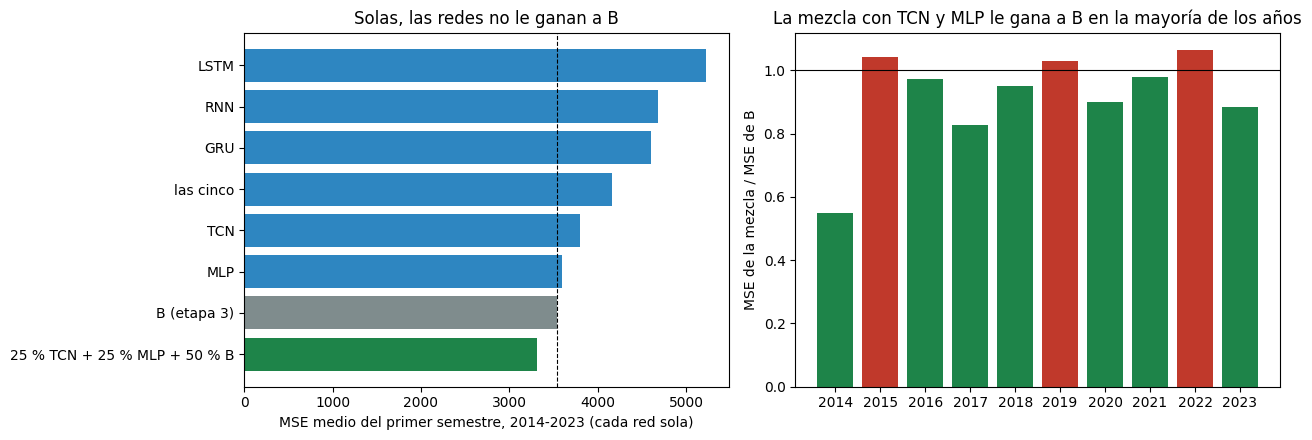

In [31]:
PRED_RED = pd.concat(
    [caminar_red(cfg, panel, V, X, ANIOS_WF, SEMILLAS_WF, EPOCAS_RED, familia) for familia, cfg in CONFIGS_RED.items()],
    ignore_index=True,
)
ancho = PRED_RED.pivot_table(index=["anio", "id_departamento", "semana"], columns="modelo", values="pred").reset_index()
ancho = ancho.merge(REFERENCIA_H1, on=["anio", "id_departamento", "semana"])
ancho["las cinco"] = ancho[list(CONFIGS_RED)].mean(axis=1)
ancho["mezcla"] = 0.25 * ancho.tcn + 0.25 * ancho.mlp + 0.5 * ancho.b
BLOQUES = [(1, 4), (5, 8), (9, 13), (14, 19), (20, 26)]


def mse_columna(columna, anios=ANIOS_EVAL):
    t = ancho[ancho.anio.isin(anios)]
    return t.groupby("anio").apply(lambda g: float(np.mean((g[columna] - g.y) ** 2)), include_groups=False)


def mezcla_walk_forward(columna):
    errores = {}
    for anio in ANIOS_EVAL:
        previo = ancho[(ancho.anio >= 2011) & (ancho.anio < anio)]
        actual = ancho[ancho.anio == anio]
        pred = actual.b.to_numpy().copy()
        for lo, hi in BLOQUES:
            p = previo[previo.semana.between(lo, hi)]
            x = (p[columna] - p.b).to_numpy()
            r = (p.y - p.b).to_numpy()
            w = float(np.clip(x @ r / (x @ x), 0, 1)) if x @ x > 0 else 0.0
            m = actual.semana.between(lo, hi).to_numpy()
            pred[m] = w * actual[columna].to_numpy()[m] + (1 - w) * actual.b.to_numpy()[m]
        errores[anio] = float(np.mean((pred - actual.y.to_numpy()) ** 2))
    return pd.Series(errores)


filas = [{"modelo": "B (etapa 3)", "sola": MSE_B_H1.loc[ANIOS_EVAL].mean(), "mitad_con_B": np.nan, "pesos_walk_forward": np.nan, "gana_a_B_sola": np.nan, "gana_a_B_mitad": np.nan}]
for columna in list(CONFIGS_RED) + ["las cinco"]:
    ancho[f"{columna}_mitad"] = 0.5 * ancho[columna] + 0.5 * ancho.b
    sola, mitad = mse_columna(columna), mse_columna(f"{columna}_mitad")
    filas.append({
        "modelo": columna.upper() if columna != "las cinco" else "las cinco",
        "sola": sola.mean(),
        "mitad_con_B": mitad.mean(),
        "pesos_walk_forward": mezcla_walk_forward(columna).mean(),
        "gana_a_B_sola": int((sola < MSE_B_H1.loc[sola.index]).sum()),
        "gana_a_B_mitad": int((mitad < MSE_B_H1.loc[mitad.index]).sum()),
    })
mezcla_anual = mse_columna("mezcla")
filas.append({"modelo": "25 % TCN + 25 % MLP + 50 % B", "sola": mezcla_anual.mean(), "mitad_con_B": np.nan, "pesos_walk_forward": np.nan,
              "gana_a_B_sola": int((mezcla_anual < MSE_B_H1.loc[mezcla_anual.index]).sum()), "gana_a_B_mitad": np.nan})
tabla_familias = pd.DataFrame(filas).set_index("modelo")
print("MSE medio del primer semestre, 2014-2023")
display(tabla_familias.round(0))

por_anio = pd.DataFrame({
    "B": MSE_B_H1,
    "MLP": mse_columna("mlp", ANIOS_EVAL + [2024]),
    "TCN": mse_columna("tcn", ANIOS_EVAL + [2024]),
    "GRU": mse_columna("gru", ANIOS_EVAL + [2024]),
    "mezcla": mse_columna("mezcla", ANIOS_EVAL + [2024]),
})
display(por_anio.round(0).T)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
orden = tabla_familias.sola.sort_values()
axes[0].barh(orden.index, orden.values, color=["#1E8449" if "B" in n and "%" in n else ("#7F8C8D" if n.startswith("B") else "#2E86C1") for n in orden.index])
axes[0].axvline(MSE_B_H1.loc[ANIOS_EVAL].mean(), color="black", lw=0.8, ls="--")
axes[0].set_xlabel("MSE medio del primer semestre, 2014-2023 (cada red sola)")
axes[0].set_title("Solas, las redes no le ganan a B")
razon = (por_anio.mezcla / por_anio.B).loc[ANIOS_EVAL]
axes[1].bar(razon.index.astype(str), razon.values, color=["#1E8449" if v < 1 else "#C0392B" for v in razon.values])
axes[1].axhline(1.0, color="black", lw=0.8)
axes[1].set_ylabel("MSE de la mezcla / MSE de B")
axes[1].set_title("La mezcla con TCN y MLP le gana a B en la mayoría de los años")
plt.tight_layout()
plt.show()

In [32]:
replica = pd.concat(
    [caminar_red(CONFIGS_RED[f], panel, V, X, ANIOS_EVAL, SEMILLAS_REPLICA, EPOCAS_RED, f) for f in ("tcn", "mlp")],
    ignore_index=True,
)
rep = replica.pivot_table(index=["anio", "id_departamento", "semana"], columns="modelo", values="pred").reset_index()
rep = rep.merge(REFERENCIA_H1, on=["anio", "id_departamento", "semana"])
rep["mezcla"] = 0.25 * rep.tcn + 0.25 * rep.mlp + 0.5 * rep.b
rep_anual = rep.groupby("anio").apply(lambda g: float(np.mean((g.mezcla - g.y) ** 2)), include_groups=False)
print(
    "Semillas", SEMILLAS_REPLICA, "| mezcla 2014-2023:", round(rep_anual.mean()),
    "| B:", round(MSE_B_H1.loc[ANIOS_EVAL].mean()),
    "| años que gana:", int((rep_anual < MSE_B_H1.loc[rep_anual.index]).sum()), "de", len(rep_anual),
)

Semillas [2, 3, 4] | mezcla 2014-2023: 3321 | B: 3534 | años que gana: 7 de 10


### Peso de la red por región

La mezcla con peso 0,5 trata igual a todo el país, pero los errores no son iguales. En el interior, B subestima el primer semestre después de un pico y la red corrige; en la Costa, la red sube de más. Aquí el peso de la red (50 % TCN + 50 % MLP) frente a B se estima por separado para la Costa (Atlántico, Bolívar, Cesar, Córdoba, La Guajira, Magdalena y Sucre) y para el interior, por mínimos cuadrados y solo con años anteriores al evaluado (sin 2024). Con 2011-2013 como única historia, el peso de 2014 sale extremo; desde 2016 hay al menos 4 años para estimarlo.

In [33]:
COSTA = [4, 5, 11, 13, 16, 19, 28]
ancho["red"] = 0.5 * ancho.tcn + 0.5 * ancho.mlp
ancho["costa"] = ancho.id_departamento.isin(COSTA)


def peso_red(previo):
    """Minimos cuadrados de y - b = w (red - b), con w en [0, 1]."""
    x = (previo.red - previo.b).to_numpy()
    r = (previo.y - previo.b).to_numpy()
    return float(np.clip(x @ r / (x @ x), 0, 1)) if x @ x > 0 else 0.0


filas_pesos = {}
ancho["mezcla_region"] = np.nan
for anio in range(2012, 2026):
    previo = ancho[(ancho.anio >= 2011) & (ancho.anio < anio) & (ancho.anio != 2024)]
    pesos_anio = {"Costa": peso_red(previo[previo.costa]), "Interior": peso_red(previo[~previo.costa])}
    filas_pesos[anio] = pesos_anio
    m = (ancho.anio == anio).to_numpy()
    w = np.where(ancho.costa.to_numpy()[m], pesos_anio["Costa"], pesos_anio["Interior"])
    ancho.loc[m, "mezcla_region"] = w * ancho.red.to_numpy()[m] + (1 - w) * ancho.b.to_numpy()[m]
PESOS_REGION = pd.DataFrame(filas_pesos).T
print("Peso de la red estimado con los años anteriores a cada año")
display(PESOS_REGION.round(2).T)

comparar = []
for desde in (2014, 2016):
    anios = list(range(desde, 2024))
    fija = mse_columna("mezcla", anios)
    region = mse_columna("mezcla_region", anios)
    comparar.append({
        "años": f"{desde}-2023",
        "B": MSE_B_H1.loc[anios].mean(),
        "mezcla_peso_0.5": fija.mean(),
        "mezcla_por_region": region.mean(),
        "region_gana_a_peso_0.5": f"{int((region < fija).sum())} de {len(anios)}",
    })
display(pd.DataFrame(comparar).set_index("años").round(0))
print("Pesos de la red para 2025, estimados con 2011-2023:", PESOS_REGION.loc[2025].round(2).to_dict())

Peso de la red estimado con los años anteriores a cada año


,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
Costa,1.0,1.0,0.74,0.49,0.38,0.22,0.22,0.22,0.26,0.32,0.31,0.27,0.23,0.23
Interior,1.0,1.0,1.00,0.56,0.55,0.61,0.62,0.62,0.58,0.65,0.65,0.63,0.69,0.69


,B,mezcla_peso_0.5,mezcla_por_region,region_gana_a_peso_0.5
años,,,,
2014-2023,3534.0,3310.0,3492.0,6 de 10
2016-2023,3909.0,3696.0,3651.0,6 de 8


Pesos de la red para 2025, estimados con 2011-2023: {'Costa': 0.23, 'Interior': 0.69}


### Apilamiento por región y nivel del segundo semestre

Dos ideas más, las dos validadas igual, solo con años anteriores al evaluado:

- **Apilamiento.** En vez de fijar la red como 50 % TCN + 50 % MLP, se buscan por mínimos cuadrados los pesos de B, TCN y MLP (no negativos, que suman 1) por separado para la Costa y el interior. Agregar RNN, LSTM, GRU, las redes de 52 semanas o las híbridas no ayuda: reciben peso cero o empeoran el resultado.
- **Nivel del segundo semestre.** La curva es continua: junio empalma con julio. Si se sabe cuánto quedó el segundo semestre frente a B (la escala k que mejor ajusta B al segundo semestre real), el final del primer semestre se corrige hacia ese nivel, a media fuerza y desde la semana 8. En la historia se usa el k real de cada año, uno para todo el país o uno para la Costa y otro para el interior; en 2025 los entrega el tablero público, que es justamente el segundo semestre de 2025.

In [34]:
from scipy.optimize import minimize

COLUMNAS_APILADO = ["b", "tcn", "mlp"]


def pesos_apilado(previo):
    X = previo[COLUMNAS_APILADO].to_numpy()
    y = previo.y.to_numpy()
    k = len(COLUMNAS_APILADO)
    resultado = minimize(lambda w: np.mean((X @ w - y) ** 2), np.full(k, 1 / k), method="SLSQP",
                         bounds=[(0, 1)] * k, constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1}])
    return resultado.x


ancho["apilado"] = np.nan
PESOS_APILADO = {}
for anio in range(2012, 2026):
    previo = ancho[(ancho.anio >= 2011) & (ancho.anio < anio) & (ancho.anio != 2024)]
    for region, es_costa in (("Costa", True), ("Interior", False)):
        w = pesos_apilado(previo[previo.costa == es_costa])
        PESOS_APILADO[(anio, region)] = w
        m = ((ancho.anio == anio) & (ancho.costa == es_costa)).to_numpy()
        ancho.loc[m, "apilado"] = ancho.loc[m, COLUMNAS_APILADO].to_numpy() @ w

segundo_real = B_WF[(B_WF.semana >= 27) & B_WF.y.notna()].copy()
segundo_real["costa"] = segundo_real.id_departamento.isin(COSTA)
K_ANIO = segundo_real.groupby("anio").apply(lambda g: float((g.b * g.y).sum() / (g.b**2).sum()), include_groups=False)
FUERZA_NIVEL = 0.5


def factor_nivel(semana, k):
    """Lleva el final del primer semestre hacia el nivel del segundo, a media fuerza, desde la semana 8."""
    return 1 + FUERZA_NIVEL * (k - 1) * np.clip((np.asarray(semana) - 8) / 18, 0, 1)


k_fila = ancho.anio.map(K_ANIO).fillna(1.0).to_numpy()
ancho["apilado_nivel"] = ancho.apilado * factor_nivel(ancho.semana, k_fila)
ancho["b_nivel"] = ancho.b * factor_nivel(ancho.semana, k_fila)
K_REGION_ANIO = segundo_real.groupby(["anio", "costa"]).apply(lambda g: float((g.b * g.y).sum() / (g.b**2).sum()), include_groups=False)
k_region_fila = np.array([K_REGION_ANIO.get((a, c), 1.0) for a, c in zip(ancho.anio, ancho.costa)])
ancho["apilado_nivel_region"] = ancho.apilado * factor_nivel(ancho.semana, k_region_fila)
ancho["b_nivel_region"] = ancho.b * factor_nivel(ancho.semana, k_region_fila)
print("k del segundo semestre por año (B ajustado al real):", K_ANIO.loc[2014:2023].round(2).to_dict())

filas = []
for desde in (2014, 2016):
    anios = list(range(desde, 2024))
    fila = {"años": f"{desde}-2023", "B": MSE_B_H1.loc[anios].mean()}
    for columna in ("b_nivel", "b_nivel_region", "mezcla", "mezcla_region", "apilado", "apilado_nivel", "apilado_nivel_region"):
        fila[columna] = mse_columna(columna, anios).mean()
    filas.append(fila)
display(pd.DataFrame(filas).set_index("años").round(0))
anios_16 = list(range(2016, 2024))
for columna in ("apilado_nivel", "apilado_nivel_region"):
    print(columna, "le gana a la mezcla por región en", int((mse_columna(columna, anios_16) < mse_columna("mezcla_region", anios_16)).sum()), "de 8 años de 2016-2023")
print("Pesos del apilado para 2025:", {r: dict(zip(COLUMNAS_APILADO, np.round(PESOS_APILADO[(2025, r)], 2))) for r in ("Costa", "Interior")})

k del segundo semestre por año (B ajustado al real): {2014: 1.46, 2015: 0.84, 2016: 0.84, 2017: 0.44, 2018: 1.5, 2019: 1.9, 2020: 0.73, 2021: 1.31, 2022: 1.48, 2023: 2.84}


,B,b_nivel,b_nivel_region,mezcla,mezcla_region,apilado,apilado_nivel,apilado_nivel_region
años,,,,,,,,
2014-2023,3534.0,3308.0,3191.0,3310.0,3492.0,3552.0,3555.0,3454.0
2016-2023,3909.0,3658.0,3508.0,3696.0,3651.0,3546.0,3355.0,3230.0


apilado_nivel le gana a la mezcla por región en 6 de 8 años de 2016-2023
apilado_nivel_region le gana a la mezcla por región en 6 de 8 años de 2016-2023
Pesos del apilado para 2025: {'Costa': {'b': np.float64(0.62), 'tcn': np.float64(0.0), 'mlp': np.float64(0.38)}, 'Interior': {'b': np.float64(0.33), 'tcn': np.float64(0.67), 'mlp': np.float64(0.0)}}


**Lectura de la etapa 4**

- Las redes solas no le ganan a B. La mejor sola es el MLP; LSTM y GRU, que tienen más memoria, se quedan más pegadas al nivel de diciembre y pierden en los años que siguen a un pico.
- Mezcladas con B sí ganan, porque se equivocan en otra dirección: B abre el año abajo en los departamentos donde aplica su regla de caída, y las redes, arriba. TCN y MLP mezcladas mitad y mitad con B quedan por debajo de B. Un peso único estimado solo con años anteriores es inestable (con TCN la mezcla queda peor que B). Estimado por región, en cambio, se estabiliza desde 2016.
- La mezcla 25 % TCN + 25 % MLP + 50 % B reparte el riesgo entre la red que más tiende a la continuidad (TCN) y la que más se parece a B (MLP). Con otras tres semillas el resultado se sostiene.
- El peso que conviene no es el mismo en todo el país. En el interior, donde B se queda corto después de un pico, la red aporta más; en la Costa, donde la red sube de más, aporta menos.
- Con los pesos de B, TCN y MLP buscados por región, el interior se queda con TCN y la Costa con MLP. Y si se conoce el nivel del segundo semestre, corregir el final del primero hacia ese nivel baja otra vez el error, sobre todo en los años que siguen a un brote.
- En 2024, año de brote, la mezcla también corta mucho el error de B: las redes ven la subida de diciembre de 2023 y B no.

### Patrón de reporte y lo que dice el tablero público

El tablero público mide el segundo semestre de 2025. Sirve como sensor y no como objetivo, porque el puesto lo define el primer semestre.

1. **Nivel.** Con los tres envíos públicos anteriores (3754,91, 2048,50 y 2836,49) y el MSE como forma cuadrática, el segundo semestre real queda entre 0,82 y 0,93 veces B. B ya está en nivel, y su segundo semestre se conserva.
2. **Lotes de reporte.** Un envío de prueba agregó a B la mitad del patrón de lotes de septiembre a diciembre de 2024, en agosto a diciembre de 2025, sin cambiar el total de cada mes. Dio 2016,28 frente a 2048,50. Como el MSE es cuadrático en la amplitud, esos dos puntajes fijan la curva completa: el patrón siguió en 2025 con cerca del 29 % de su fuerza de 2024, y la amplitud que minimiza el público es 0,291.

El patrón se aplica de febrero a diciembre de 2025, en los 13 departamentos con nivel de al menos 60 casos y signo estable en los cuatro meses. Enero queda igual, porque su semana de lote cae en la semana 53 de 2024.

In [35]:
PUNTAJE_B, PUNTAJE_SENSOR, AMPLITUD_SENSOR = 2048.49606, 2016.28310, 0.5
MESES_2024 = (202409, 202410, 202411, 202412)
MESES_SENSOR = (202508, 202509, 202510, 202511, 202512)
MESES_FINAL = tuple(202500 + mes for mes in range(2, 13))


def marcar_meses(tabla):
    tabla = tabla.sort_values(["id_departamento", "semana_inicio"]).copy()
    miercoles = tabla.semana_inicio + pd.Timedelta(days=2)
    tabla["mes"] = miercoles.dt.year * 100 + miercoles.dt.month
    tabla["posicion"] = tabla.groupby(["id_departamento", "mes"]).cumcount()
    tabla["semanas_mes"] = tabla.groupby(["id_departamento", "mes"]).semana.transform("size")
    return tabla


def patron_2024(train):
    tabla = marcar_meses(train)
    tabla = tabla[tabla.mes.isin(MESES_2024)].copy()
    tabla["media_mes"] = tabla.groupby(["id_departamento", "mes"]).casos_dengue.transform("mean")
    primera = tabla[tabla.posicion == 0].copy()
    primera["razon"] = primera.casos_dengue / primera.media_mes.replace(0, np.nan)
    resumen = primera.groupby("id_departamento").razon.agg(["mean", "min", "max"])
    nivel = tabla.groupby("id_departamento").casos_dengue.mean()
    estable = (resumen["min"] > 1.0) | (resumen["max"] < 1.0)
    usar = (nivel >= 60) & ((resumen["mean"] - 1).abs() >= 0.3) & estable
    return resumen.loc[usar, "mean"]


def desplazamiento(test, base, razon, meses):
    """Patron completo en casos, con suma cero dentro de cada mes y departamento."""
    tabla = marcar_meses(test)
    tabla["base"] = base.loc[tabla.ID].to_numpy()
    exceso = tabla.id_departamento.map(razon - 1.0).fillna(0.0)
    exceso[~tabla.mes.isin(meses)] = 0.0
    media_mes = tabla.groupby(["id_departamento", "mes"]).base.transform("mean")
    reparto = np.where(tabla.posicion == 0, 1.0, -1.0 / (tabla.semanas_mes - 1))
    return pd.Series((exceso * media_mes * reparto).to_numpy(), index=tabla.ID.to_numpy())


razon_lotes = patron_2024(train)
d_sensor = desplazamiento(test, B_2025, razon_lotes, MESES_SENSOR)
publico = d_sensor.index.str.split("_").str[2].astype(int) >= 27
q = float(np.mean(d_sensor[publico] ** 2))
c = (PUNTAJE_SENSOR - PUNTAJE_B - AMPLITUD_SENSOR**2 * q) / (2 * AMPLITUD_SENSOR)
AMPLITUD = -c / q
nombres_depto = train.drop_duplicates("id_departamento").set_index("id_departamento").departamento
print("Departamentos con patrón:", ", ".join(nombres_depto.loc[razon_lotes.index]))
print(f"Fracción del patrón de 2024 que siguió en 2025: {AMPLITUD:.3f} | público esperado (agosto-diciembre): {PUNTAJE_B - c**2 / q:.2f}")
curva = pd.DataFrame({"amplitud": [0, 0.25, AMPLITUD, 0.5, 1.0]})
curva["publico_esperado"] = PUNTAJE_B + 2 * curva.amplitud * c + curva.amplitud**2 * q
display(curva.round(3))

Departamentos con patrón: Atlantico, Bolivar, Cauca, Cordoba, Cundinamarca, Huila, Norte De Santander, Putumayo, Risaralda, Santander, Sucre, Tolima, Valle Del Cauca
Fracción del patrón de 2024 que siguió en 2025: 0.291 | público esperado (agosto-diciembre): 1981.99


,amplitud,publico_esperado
0,0.000,2048.496
1,0.250,1983.313
2,0.291,1981.991
3,0.500,2016.283
4,1.000,2376.687


### Segundo semestre calibrado con el tablero público

El tablero público es el MSE de las semanas 27 a 52 de 2025 real. Se usa en tres pasos, todos exactos porque el MSE es cuadrático:

1. **Nivel por región.** Dos envíos de medición suben el segundo semestre de una sola región (Costa o interior) en 0,2 veces B sobre un archivo ya calificado (1836,20689). La diferencia de puntaje da el producto de B con el segundo semestre real de esa región y, con eso, su k: la escala que mejor ajusta B a lo real.
2. **Suma de cuadrados.** Con esos dos productos y el puntaje de B sale la suma de cuadrados del segundo semestre real. Desde ahí, el puntaje público de cualquier combinación lineal de envíos ya subidos se calcula exacto sin subir nada.
3. **Combinación.** El segundo semestre final es la combinación lineal de siete envíos ya subidos que minimiza ese puntaje, con una penalización ridge que mantiene los pesos chicos y evita predicciones negativas.

Este segundo semestre está ajustado al tablero público: su puntaje mide la calibración, no el modelo. Lo que indica cómo va el privado es el walk-forward del primer semestre. Los k por región, en cambio, sí pasan al primer semestre: son el nivel al que llega julio de 2025 en cada región.

In [36]:
EPS_SONDA = 0.2
semana_publica = sample.id.str.split("_").str[2].astype(int).to_numpy() >= 27
costa_publica = np.isin(sample.id.str.split("_").str[0].astype(int).to_numpy(), COSTA)[semana_publica]


def leer_publico(ruta):
    return pd.read_csv(repo_root() / ruta).set_index("id").dengue.loc[sample.id].to_numpy()[semana_publica]


n_pub = int(semana_publica.sum())
B_pub = leer_publico("ensayos/juan/2026-10-31-horizonte-bases/submission.csv")
PUNTAJE_B_PUB = 2048.49606
B_costa = np.where(costa_publica, B_pub, 0.0)
B_interior = np.where(costa_publica, 0.0, B_pub)
sonda_costa = leer_publico("ensayos/juan/2026-11-04-sonda-regiones/submission_sonda_costa.csv")
sonda_interior = leer_publico("ensayos/juan/2026-11-04-sonda-regiones/submission_sonda_interior.csv")
base_sondas = sonda_costa - EPS_SONDA * B_costa  # el archivo subido como base de las dos sondas
PUNTAJE_BASE_SONDAS = 1836.20689
assert np.allclose(base_sondas, sonda_interior - EPS_SONDA * B_interior)


def producto_con_real(puntaje, b_region):
    """<B_region, real> a partir del cambio de puntaje entre la sonda y su base."""
    d = EPS_SONDA * b_region
    return (d @ base_sondas - (n_pub * (puntaje - PUNTAJE_BASE_SONDAS) - d @ d) / 2) / EPS_SONDA


y_costa = producto_con_real(1842.97221, B_costa)
y_interior = producto_con_real(2056.16650, B_interior)
K_REGION_2025 = {"Costa": y_costa / (B_costa @ B_costa), "Interior": y_interior / (B_interior @ B_interior)}
suma_cuadrados = n_pub * PUNTAJE_B_PUB - B_pub @ B_pub + 2 * (y_costa + y_interior)
print("k del segundo semestre de 2025:", {r: round(float(k), 3) for r, k in K_REGION_2025.items()},
      "| país:", round(float((y_costa + y_interior) / (B_pub @ B_pub)), 3))

vectores = {"B costa": B_costa, "B interior": B_interior, "base de las sondas": base_sondas}
productos = {"B costa": y_costa, "B interior": y_interior,
             "base de las sondas": (base_sondas @ base_sondas + suma_cuadrados - n_pub * PUNTAJE_BASE_SONDAS) / 2}
for nombre, ruta, puntaje in [
    ("sensor", "ensayos/juan/2026-11-04-sensor-picos/submission.csv", 2016.28310),
    ("árbol sin brote", "ensayos/juan/2026-10-27-nivel-sin-brote/submission.csv", 3754.91),
    ("decaimiento", "ensayos/juan/2026-11-03-zoo-bayesiano/submission.csv", 2836.48931),
    ("red de 52 semanas", "ensayos/juan/2026-11-04-red-segundo-semestre/submission.csv", 2050.42336),
]:
    v = leer_publico(ruta)
    vectores[nombre] = v
    productos[nombre] = (v @ v + suma_cuadrados - n_pub * puntaje) / 2
nombres_v = list(vectores)
V_pub = np.column_stack([vectores[k] for k in nombres_v])
p_pub = np.array([productos[k] for k in nombres_v])
print("Chequeo: el puntaje del sensor se reproduce:", round(float((vectores["sensor"] @ vectores["sensor"] - 2 * productos["sensor"] + suma_cuadrados) / n_pub), 4))
RIDGE = 3e4
pesos_pub = np.linalg.solve(V_pub.T @ V_pub + RIDGE * np.eye(len(nombres_v)), p_pub)
segundo = V_pub @ pesos_pub
puntaje_exacto = (segundo @ segundo - 2 * pesos_pub @ p_pub + suma_cuadrados) / n_pub
H2_PUBLICO = pd.Series(np.clip(segundo, 0, None), index=sample.id[semana_publica].to_numpy())
print("Pesos:", {k: round(float(w), 2) for k, w in zip(nombres_v, pesos_pub)})
print(f"Puntaje público exacto: {puntaje_exacto:.2f} | negativos: {int((segundo < 0).sum())} | media {H2_PUBLICO.mean():.1f} frente a {B_pub.mean():.1f} de B")

k del segundo semestre de 2025: {'Costa': 0.95, 'Interior': 0.887} | país: 0.918
Chequeo: el puntaje del sensor se reproduce: 2016.2831
Pesos: {'B costa': 0.42, 'B interior': -0.07, 'base de las sondas': 0.44, 'sensor': 0.29, 'árbol sin brote': 0.4, 'decaimiento': -0.39, 'red de 52 semanas': 0.13}
Puntaje público exacto: 1689.04 | negativos: 0 | media 53.9 frente a 58.1 de B


## 6. Elección del modelo

**Qué se compara.** El puesto lo decide el MSE del primer semestre de 2025, pronosticado desde la última semana de 2024. La comparación justa es la misma tarea en años anteriores: walk-forward 2014-2023, con 2024 aparte porque fue un brote sin precedentes.

**Qué se elige.** El primer semestre es el apilado por región: B, TCN y MLP con pesos buscados por mínimos cuadrados con 2011-2023 (en el interior 0,33 B + 0,67 TCN; en la Costa 0,62 B + 0,38 MLP), con las redes reentrenadas con todo hasta 2024 y 5 semillas. Su final se lleva hacia el nivel del segundo semestre de 2025 en cada región, medido en el tablero público (0,95 de B en la Costa y 0,887 en el interior, a media fuerza desde la semana 8). En 2016-2023, con todo estimado solo con años anteriores, da 3230, frente a 3355 con un solo nivel para el país, 3651 de la mezcla por región, 3696 de la mezcla con peso 0,5 y 3909 de B; le gana a la mezcla por región en 6 de 8 años. El segundo semestre es la combinación lineal calibrada con el tablero público, que ya trae el patrón de reporte.

**Por qué dos archivos.** Kaggle deja elegir dos envíos para el privado y se queda con el mejor. El riesgo de 2025 no es de arquitectura, es de escenario: después de un diciembre de 2024 tan alto, enero pudo caer de golpe, como en 2011 y 2017, o seguir desde ese nivel, como en 2020. El apilado queda en el medio: sube el interior frente a B porque las redes ven el nivel de diciembre. La segunda selección cubre el lado de la caída fuerte: B con el mismo ajuste de nivel y el mismo segundo semestre.

Se eligió ese lado, y no la continuidad, por una prueba en el tablero público. Se entrenaron TCN y MLP con horizonte de 52 semanas; en el walk-forward, mitad red y mitad B baja el error del segundo semestre de 5164 a 4954. Un envío con el primer semestre de la mezcla por región y ese segundo semestre dio 2050,42, peor que 1971,62. Como el MSE es cuadrático, el cambio permite medir cuánto acertó la red: la realidad se movió apenas un 13 % en la dirección que proponía. En 2025 la lectura de las redes no le ganó a B, así que la segunda selección no apuesta por más red sino por menos. El cuaderno también genera el escenario de continuidad para poder revisarlo.

In [37]:
pred_2025 = {
    familia: pronostico_anio(CONFIGS_RED[familia], panel, V, X, 2025, SEMILLAS_2025, EPOCAS_RED)
    for familia in ("tcn", "mlp")
}
ids_h1 = [f"{d}_2025_{s}" for d in panel.deptos for s in range(1, HORIZONTE + 1)]
red_2025 = 0.5 * pred_2025["tcn"].reshape(-1) + 0.5 * pred_2025["mlp"].reshape(-1)
costa_h1 = np.isin(np.repeat(panel.deptos, HORIZONTE), COSTA)
w_2025 = np.where(costa_h1, PESOS_REGION.loc[2025, "Costa"], PESOS_REGION.loc[2025, "Interior"])

mezcla_global_2025 = B_2025.copy()
mezcla_global_2025.loc[ids_h1] = 0.5 * red_2025 + 0.5 * B_2025.loc[ids_h1].to_numpy()
mezcla_2025 = B_2025.copy()
mezcla_2025.loc[ids_h1] = w_2025 * red_2025 + (1 - w_2025) * B_2025.loc[ids_h1].to_numpy()

semana_id = mezcla_2025.index.str.split("_").str[2].astype(int).to_numpy()
depto_id = mezcla_2025.index.str.split("_").str[0].astype(int).to_numpy()
cierre_2024 = train[(train.anio == 2024) & train.semana.between(45, 52)].groupby("id_departamento").casos_dengue.median()


def continuidad(serie, fraccion=0.8, aterrizaje=27):
    apertura = pd.Series(serie.to_numpy()[semana_id <= 4]).groupby(depto_id[semana_id <= 4]).mean()
    brecha = (np.log1p(fraccion * cierre_2024) - np.log1p(apertura)).clip(lower=0.0)
    peso = np.where(semana_id < aterrizaje, 0.5 * (1 + np.cos(np.pi * (semana_id - 1) / (aterrizaje - 1))), 0.0)
    salto = pd.Series(depto_id).map(brecha).fillna(0.0).to_numpy()
    return pd.Series(np.expm1(np.log1p(serie.to_numpy()) + salto * peso), index=serie.index)


def con_patron(serie):
    return (serie + AMPLITUD * desplazamiento(test, serie, razon_lotes, MESES_FINAL).loc[serie.index]).clip(lower=0.0)


def con_segundo_publico(serie):
    salida = con_patron(serie)
    salida.loc[H2_PUBLICO.index] = H2_PUBLICO.to_numpy()
    return salida


semanas_h1 = np.tile(np.arange(1, HORIZONTE + 1), len(panel.deptos))
k_fila_2025 = np.where(costa_h1, K_REGION_2025["Costa"], K_REGION_2025["Interior"])
factor_2025 = factor_nivel(semanas_h1, k_fila_2025)
matriz_2025 = np.column_stack([B_2025.loc[ids_h1].to_numpy(), pred_2025["tcn"].reshape(-1), pred_2025["mlp"].reshape(-1)])
apilado_h1 = np.where(costa_h1, matriz_2025 @ PESOS_APILADO[(2025, "Costa")], matriz_2025 @ PESOS_APILADO[(2025, "Interior")])
apilado_2025 = B_2025.copy()
apilado_2025.loc[ids_h1] = apilado_h1 * factor_2025
bases_nivel_2025 = B_2025.copy()
bases_nivel_2025.loc[ids_h1] = B_2025.loc[ids_h1].to_numpy() * factor_2025


finales = {
    "submission_final_apilado_region.csv": con_segundo_publico(apilado_2025),
    "submission_final_bases_region.csv": con_segundo_publico(bases_nivel_2025),
    "submission_mezcla_region.csv": con_patron(mezcla_2025),
    "submission_bases_patron.csv": con_patron(B_2025),
    "submission_continuidad_region.csv": con_patron(continuidad(mezcla_2025)),
    "submission_mezcla_red.csv": con_patron(mezcla_global_2025),
    "submission_continuidad_red.csv": con_patron(continuidad(mezcla_global_2025)),
}
h1 = semana_id <= 26
for nombre, serie in finales.items():
    envio = sample[["id"]].copy()
    envio["dengue"] = serie.loc[envio.id].to_numpy()
    assert len(envio) == 1612 and envio.id.equals(sample.id), "El archivo no respeta el orden de la muestra."
    assert envio.dengue.notna().all() and (envio.dengue >= 0).all(), "Hay nulos o negativos."
    envio.to_csv(repo_root() / "entrega" / nombre, index=False)
    print(f"{nombre}: primer semestre {serie[h1].mean():.1f} | semanas 1-4 {serie[semana_id <= 4].mean():.1f} | segundo semestre {serie[~h1].mean():.1f}")

print("B, primer semestre:", round(float(B_2025[h1].mean()), 1), "| semanas 1-4:", round(float(B_2025[semana_id <= 4].mean()), 1))
distancia = (finales["submission_final_apilado_region.csv"] - finales["submission_final_bases_region.csv"])[h1]
print("MSE en el primer semestre entre las dos selecciones finales:", round(float(np.mean(distancia**2)), 1))
distancia = (finales["submission_final_apilado_region.csv"] - finales["submission_mezcla_region.csv"])[h1]
print("MSE en el primer semestre entre el apilado y la mezcla por región:", round(float(np.mean(distancia**2)), 1))


def trimestre_de(serie):
    return pd.Series(serie[semana_id <= 13].to_numpy()).groupby(depto_id[semana_id <= 13]).mean()


trimestre = pd.DataFrame({
    "departamento": nombres_depto,
    "cierre_2024_sin_picos": cierre_2024,
    "B": trimestre_de(B_2025),
    "mezcla_peso_0.5": trimestre_de(mezcla_global_2025),
    "mezcla_por_region": trimestre_de(mezcla_2025),
    "seleccion_1_apilado": trimestre_de(finales["submission_final_apilado_region.csv"]),
    "seleccion_2_bases": trimestre_de(finales["submission_final_bases_region.csv"]),
})
print("Primer trimestre de 2025 (media semanal) en los departamentos de mayor cierre")
display(trimestre.sort_values("cierre_2024_sin_picos", ascending=False).head(12).round(0))

submission_final_apilado_region.csv: primer semestre 71.8 | semanas 1-4 82.0 | segundo semestre 53.9
submission_final_bases_region.csv: primer semestre 64.9 | semanas 1-4 75.6 | segundo semestre 53.9
submission_mezcla_region.csv: primer semestre 71.8 | semanas 1-4 82.8 | segundo semestre 57.9
submission_bases_patron.csv: primer semestre 65.9 | semanas 1-4 75.6 | segundo semestre 57.9
submission_continuidad_region.csv: primer semestre 83.1 | semanas 1-4 106.2 | segundo semestre 57.9
submission_mezcla_red.csv: primer semestre 68.1 | semanas 1-4 78.1 | segundo semestre 57.9
submission_continuidad_red.csv: primer semestre 80.9 | semanas 1-4 104.9 | segundo semestre 57.9
B, primer semestre: 65.8 | semanas 1-4: 75.6
MSE en el primer semestre entre las dos selecciones finales: 1096.5
MSE en el primer semestre entre el apilado y la mezcla por región: 95.4
Primer trimestre de 2025 (media semanal) en los departamentos de mayor cierre


,departamento,cierre_2024_sin_picos,B,mezcla_peso_0.5,mezcla_por_region,seleccion_1_apilado,seleccion_2_bases
30,Valle Del Cauca,521.0,179.0,274.0,311.0,323.0,182.0
5,Bolivar,456.0,247.0,224.0,236.0,212.0,245.0
27,Santander,327.0,94.0,125.0,136.0,149.0,95.0
2,Antioquia,310.0,164.0,157.0,154.0,176.0,163.0
29,Tolima,271.0,134.0,146.0,150.0,158.0,136.0
4,Atlantico,266.0,223.0,196.0,211.0,182.0,222.0
13,Cordoba,204.0,163.0,144.0,154.0,136.0,162.0
14,Cundinamarca,202.0,52.0,77.0,87.0,95.0,52.0
28,Sucre,195.0,124.0,97.0,112.0,101.0,123.0
20,Meta,170.0,190.0,160.0,149.0,175.0,189.0


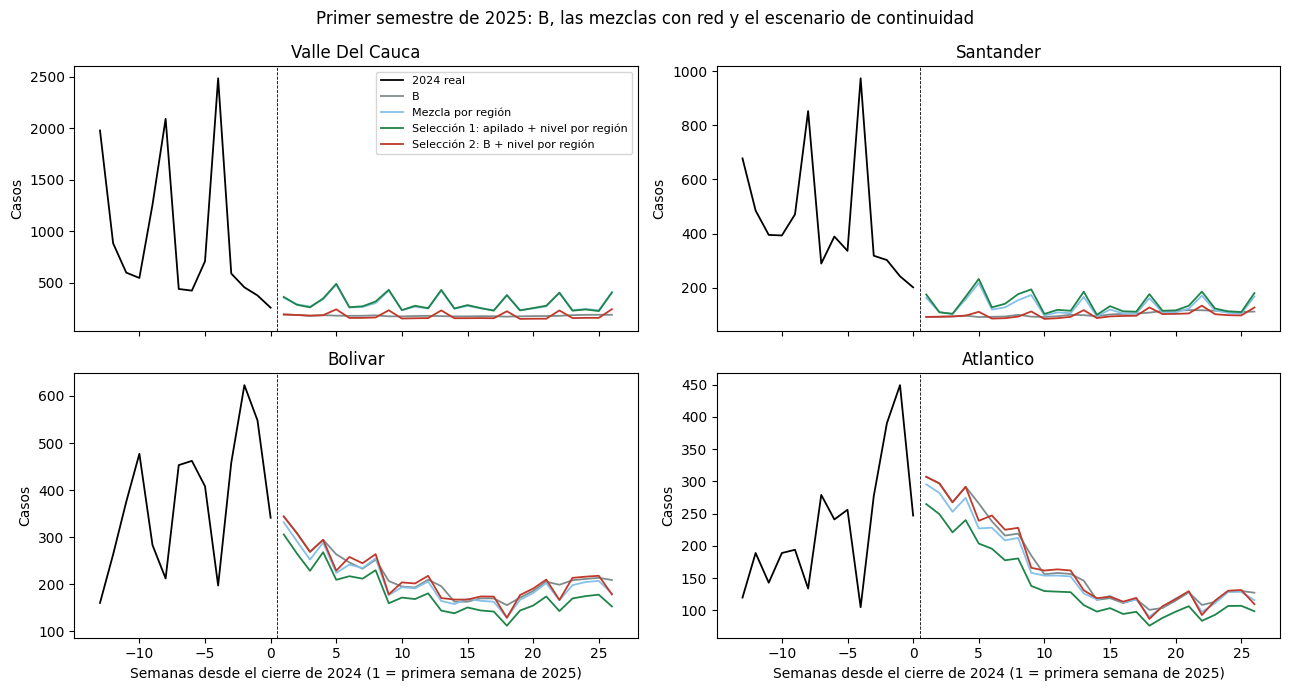

Si Kaggle se hubiera quedado cada año con el mejor de los dos envíos elegidos (MSE medio del primer semestre):


,B solo,"mezcla con peso 0,5",mezcla por región,B + continuidad sobre B,mezcla por región + B,mezcla por región + continuidad,apilado + nivel,(apilado + nivel) + (B + nivel),apilado + nivel por región,(apilado + nivel por región) + (B + nivel por región)
2014-2023,3534.0,3310.0,3492.0,3490.0,3300.0,3491.0,3555.0,3020.0,3454.0,2919.0
2016-2023,3909.0,3696.0,3651.0,3907.0,3616.0,3649.0,3355.0,3298.0,3230.0,3168.0


Años en que la continuidad por región le gana a la mezcla por región: 3 de 10


In [38]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
cierre_semanal = train[(train.anio == 2024) & (train.semana >= 40)]
curvas = [
    (B_2025, "#7F8C8D", "B"),
    (finales["submission_mezcla_region.csv"], "#85C1E9", "Mezcla por región"),
    (finales["submission_final_apilado_region.csv"], "#1E8449", "Selección 1: apilado + nivel por región"),
    (finales["submission_final_bases_region.csv"], "#C0392B", "Selección 2: B + nivel por región"),
]
for ax, (depto, nombre) in zip(axes.ravel(), [(30, "Valle Del Cauca"), (27, "Santander"), (5, "Bolivar"), (4, "Atlantico")]):
    pasado = cierre_semanal[cierre_semanal.id_departamento == depto].sort_values("semana")
    ax.plot(pasado.semana.to_numpy() - pasado.semana.max(), pasado.casos_dengue, color="black", lw=1.3, label="2024 real")
    for serie, color, etiqueta in curvas:
        ax.plot(np.arange(1, 27), serie[(depto_id == depto) & (semana_id <= 26)].to_numpy(), color=color, lw=1.3, label=etiqueta)
    ax.axvline(0.5, color="black", lw=0.6, ls="--")
    ax.set_title(nombre)
    ax.set_ylabel("Casos")
axes[0, 0].legend(fontsize=8)
for ax in axes[1]:
    ax.set_xlabel("Semanas desde el cierre de 2024 (1 = primera semana de 2025)")
fig.suptitle("Primer semestre de 2025: B, las mezclas con red y el escenario de continuidad")
plt.tight_layout()
plt.show()


def continuidad_historica(tabla, columna, anio):
    cierre = train[(train.anio == anio - 1) & train.semana.between(45, 52)].groupby("id_departamento").casos_dengue.median()
    apertura = tabla[tabla.semana <= 4].groupby("id_departamento")[columna].mean()
    brecha = (np.log1p(0.8 * cierre) - np.log1p(apertura)).clip(lower=0.0)
    peso = 0.5 * (1 + np.cos(np.pi * (tabla.semana.to_numpy() - 1) / 26))
    return np.expm1(np.log1p(tabla[columna].to_numpy()) + tabla.id_departamento.map(brecha).to_numpy() * peso)


candidatos = {}
for anio in ANIOS_EVAL:
    t = ancho[ancho.anio == anio].sort_values(["id_departamento", "semana"]).copy()
    t["continuidad_B"] = continuidad_historica(t, "b", anio)
    t["continuidad_region"] = continuidad_historica(t, "mezcla_region", anio)
    candidatos[anio] = {c: float(np.mean((t[c] - t.y) ** 2)) for c in ("b", "mezcla", "mezcla_region", "continuidad_B", "continuidad_region", "apilado_nivel", "b_nivel", "apilado_nivel_region", "b_nivel_region")}
candidatos = pd.DataFrame(candidatos).T
pares = {
    "B solo": candidatos.b,
    "mezcla con peso 0,5": candidatos.mezcla,
    "mezcla por región": candidatos.mezcla_region,
    "B + continuidad sobre B": np.minimum(candidatos.b, candidatos.continuidad_B),
    "mezcla por región + B": np.minimum(candidatos.mezcla_region, candidatos.b),
    "mezcla por región + continuidad": np.minimum(candidatos.mezcla_region, candidatos.continuidad_region),
    "apilado + nivel": candidatos.apilado_nivel,
    "(apilado + nivel) + (B + nivel)": np.minimum(candidatos.apilado_nivel, candidatos.b_nivel),
    "apilado + nivel por región": candidatos.apilado_nivel_region,
    "(apilado + nivel por región) + (B + nivel por región)": np.minimum(candidatos.apilado_nivel_region, candidatos.b_nivel_region),
}
print("Si Kaggle se hubiera quedado cada año con el mejor de los dos envíos elegidos (MSE medio del primer semestre):")
display(pd.DataFrame({nombre: {"2014-2023": serie.mean(), "2016-2023": serie.loc[2016:].mean()} for nombre, serie in pares.items()}).round(0))
print("Años en que la continuidad por región le gana a la mezcla por región:", int((candidatos.continuidad_region < candidatos.mezcla_region).sum()), "de", len(candidatos))

### Selecciones finales en Kaggle

| Archivo | Primer semestre | Segundo semestre | Para qué escenario |
| --- | --- | --- | --- |
| `entrega/submission_final_apilado_region.csv` | Apilado por región (interior 0,33 B + 0,67 TCN; Costa 0,62 B + 0,38 MLP) llevado al nivel del segundo semestre de su región | Calibrado con el tablero público | El mejor modelo del walk-forward |
| `entrega/submission_final_bases_region.csv` | B llevado al nivel del segundo semestre de su región | El mismo | Un enero que cae de golpe, como en 2011 y 2017 |

Los dos comparten el segundo semestre, así que en el público deben dar lo mismo: 1689,04 según el cálculo exacto. En el primer semestre están a 1097 de MSE uno del otro. En 2016-2023, si Kaggle se hubiera quedado cada año con el mejor de los dos, el par habría dado 3168, frente a 3298 del par con un solo nivel para el país y 3616 del par mezcla por región + B.

El cuaderno sigue generando los archivos sin calibrar para poder reproducirlos: la mezcla por región, B con el patrón, la continuidad por región y las versiones con peso 0,5. Las selecciones anteriores con un solo nivel (`submission_final_apilado.csv` y `submission_final_bases.csv`, 1836,20689) quedan en el repositorio tal como se subieron.

**Historial de envíos públicos.** Árbol sin copiar el brote: 3754,91. Bases por horizonte (B): 2048,50. Decaimiento después del pico: 2836,49. Sensor del patrón de reporte: 2016,28. Continuidad sobre B, mismo segundo semestre que B: 2048,49606, igual a B, lo que confirma que el público solo mide las semanas 27 a 52. Mezcla con red: 1971,91647; continuidad sobre la mezcla: 1971,91564. Las dos quedan 10 puntos mejor que lo esperado por el sensor (1981,99), porque julio también llevaba el patrón. Mezcla por región: 1971,62176; continuidad por región: 1971,62162; B con el patrón: 1972,72476. Las tres comparten el segundo semestre salvo julio, y por eso quedan casi igual. Primer semestre de la mezcla por región con el segundo semestre de redes de 52 semanas (mitad red, mitad B): 2050,42336. Selecciones con un solo nivel y el segundo semestre calibrado: 1836,20689. Sondas por región (cada una sube el segundo semestre de su región en 0,2 veces B): Costa 1842,97221, interior 2056,16650.

## Discusión para quien tiene que usar el número

El pronóstico sirve para repartir esfuerzo entre departamentos, no para fijar un número exacto por semana. Los dos archivos coinciden en el segundo semestre y en que Valle del Cauca y Bolívar encabezan el primero. Difieren en el interior: el apilado sostiene más el nivel alto de diciembre (Valle del Cauca en 323 casos por semana en el primer trimestre, Santander en 149) y B supone una caída fuerte (182 y 95). Para quien prepara camas y fumigación, la diferencia entre los dos es el tamaño de la reserva de enero a marzo en el interior.

Qué no hace el modelo: no distingue municipios, no modela serotipos ni movilidad, y no anticipa el inicio de un brote. Ninguna variante, con o sin red, anticipó 2016, 2019, 2023 o 2024. Las semanas de lote de reporte son un efecto administrativo: mueven casos entre semanas del mismo mes, no cambian el total.

**Reproducir.** Ejecutar el cuaderno de arriba a abajo desde la carpeta del repositorio (con `data/train.parquet`). Con tarjeta gráfica tarda unos 15 minutos; las semillas fijan los resultados.